In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Quy đổi theo giả thiết đã thống nhất: raw = lambda × 1000; xăng chuẩn 14,7.
# Giữ nguyên các cột gốc, chỉ tạo thêm cột AFR suy ra.
STOICH_AFR = 14.7
LAMBDA_RAW_SCALE = 1000.0

def raw_to_afr(values):
    return values / LAMBDA_RAW_SCALE * STOICH_AFR

# Chọn một tệp dữ liệu mẫu.
file = Path("car_data/20180713-home2mimos.csv")
# file = Path("car_data/20180713-mimos2home.csv")
lines = file.read_text(encoding="utf-8-sig").splitlines()

# Tìm dòng kết thúc metadata và lấy tên các kênh.
log_index = next(
    i for i, line in enumerate(lines)
    if line.startswith("Log :")
)
columns = ["Time"] + [
    line.split(" : ", 1)[1]
    for line in lines[:log_index]
    if line.startswith("Channel :")
]

# Đọc bảng dữ liệu, bỏ qua metadata.
df1 = pd.read_csv(file, skiprows=log_index + 1, names=columns)

# print("Số dòng, số cột:", df1.shape)
# df1.head()

# Kiểu dữ liệu và số giá trị có mặt trong từng cột
# df1.info()

In [2]:
print("\n".join(lines[:log_index + 1]))

%DataLog%
DataLogVersion : 1.0
Software : ECU Manager
SoftwareVersion : 1.1.14.0
DownloadDateTime : 20180713 08:37:23
Channel : BaseFuel
Type : Percentage
DisplayMaxMin : 2000,0
Channel : BaseIgnition
Type : AngleIgnSprt2K
DisplayMaxMin : 800,0
Channel : TargetAFR
Type : AFR
DisplayMaxMin : 2000,200
Channel : FuelCoolantTempCorrection
Type : Percentage1For1
DisplayMaxMin : 250,-100
Channel : FuelAirTempCorrection
Type : Percentage
DisplayMaxMin : 500,-500
Channel : ThrottlePosition
Type : Percentage
DisplayMaxMin : 1000,0
Channel : AirTemp
Type : Temperature
DisplayMaxMin : 4231,2331
Channel : CoolantTemp
Type : Temperature
DisplayMaxMin : 4231,2331
Channel : LambdaSensor1
Type : AFR
DisplayMaxMin : 2000,200
Channel : RPM
Type : EngineSpeed
DisplayMaxMin : 10000,0
Channel : Load
Type : Pressure
DisplayMaxMin : 1013,13
Channel : BatteryVoltage
Type : BatteryVoltage
DisplayMaxMin : 16000,8000
Channel : EngineRunningTime
Type : Time_s
DisplayMaxMin : 10000,0
Channel : DeltaLoad
Type : Per

In [3]:
df_work = df1.copy()

# Giữ thông tin nguồn và thứ tự bản ghi
df_work["trip_id"] = file.stem
df_work["source_row"] = range(len(df_work))

# Chuyển thời gian, giữ nguyên cột Time ban đầu
df_work["time_parsed"] = pd.to_timedelta(
    df_work["Time"], errors="coerce"
)

df_work["elapsed_s"] = (
    df_work["time_parsed"] - df_work["time_parsed"].iloc[0]
).dt.total_seconds()

df_work["dt_s"] = df_work["elapsed_s"].diff()

# Đánh dấu để kiểm tra, chưa xóa bản ghi
df_work["duplicate_time"] = df_work["Time"].duplicated(
    keep=False
)
df_work["time_backwards"] = df_work["dt_s"].lt(0)

df_work[["Time", "elapsed_s", "RPM"]].head(10)

,Time,elapsed_s,RPM
0,07:54:58.000,0.000,1164.0
1,07:54:58.031,0.031,1155.0
2,07:54:58.047,0.047,NaN
3,07:54:58.062,0.062,1168.0
4,07:54:58.078,0.078,NaN
5,07:54:58.109,0.109,NaN
6,07:54:58.140,0.140,1168.0
7,07:54:58.156,0.156,1169.0
8,07:54:58.250,0.250,1174.0
9,07:54:58.265,0.265,1180.0


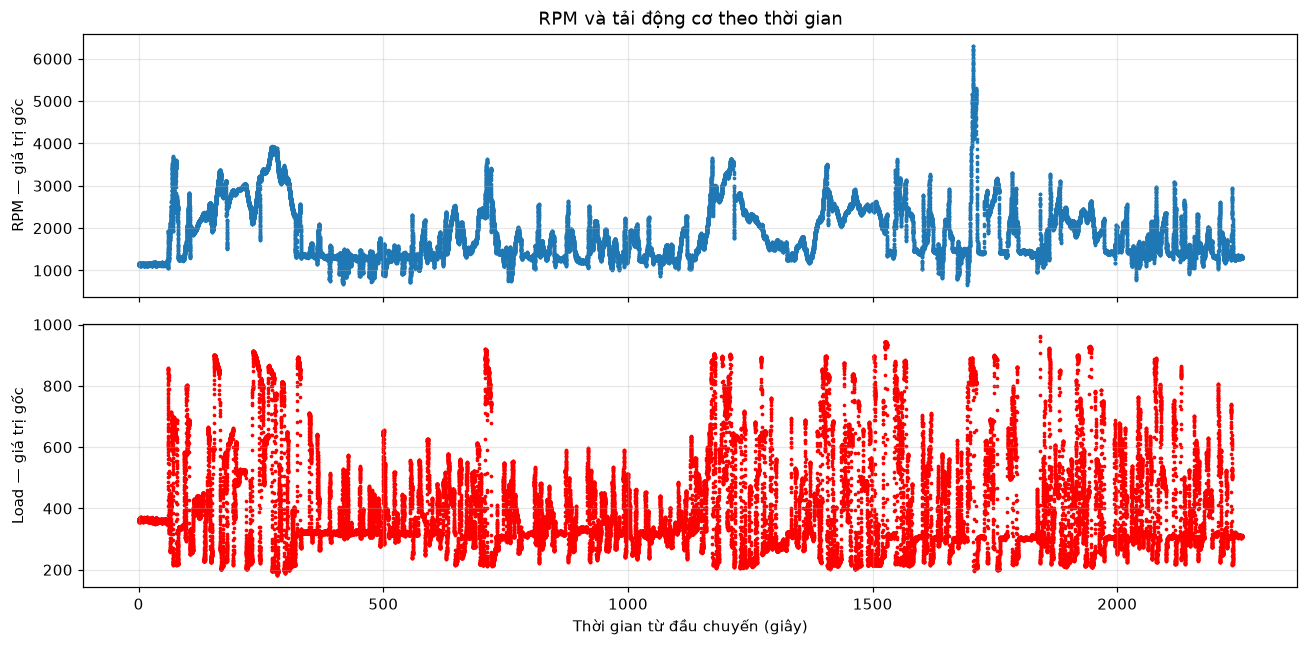

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].scatter(df_work["elapsed_s"], df_work["RPM"], s=2)
axes[0].set_ylabel("RPM — giá trị gốc")
axes[0].set_title("RPM và tải động cơ theo thời gian")

axes[1].scatter(df_work["elapsed_s"], df_work["Load"], color='red', s=2)
axes[1].set_ylabel("Load — giá trị gốc")
axes[1].set_xlabel("Thời gian từ đầu chuyến (giây)")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

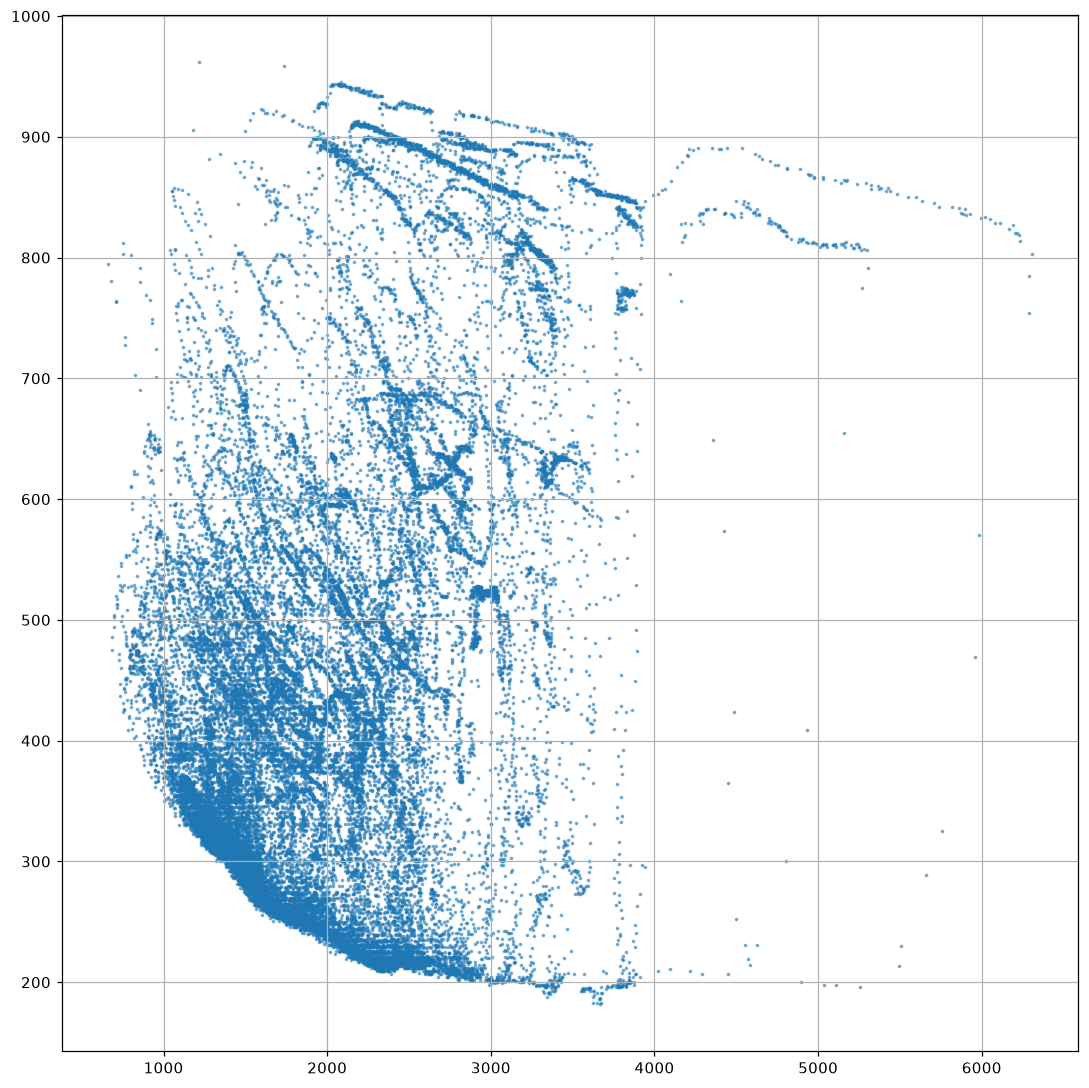

In [5]:
plt.figure(figsize=(10, 10))

plt.scatter(
    df_work["RPM"], df_work["Load"],
    s=2, alpha=0.5, label="RPM - Load"
)
plt.grid()
plt.tight_layout()
plt.show()

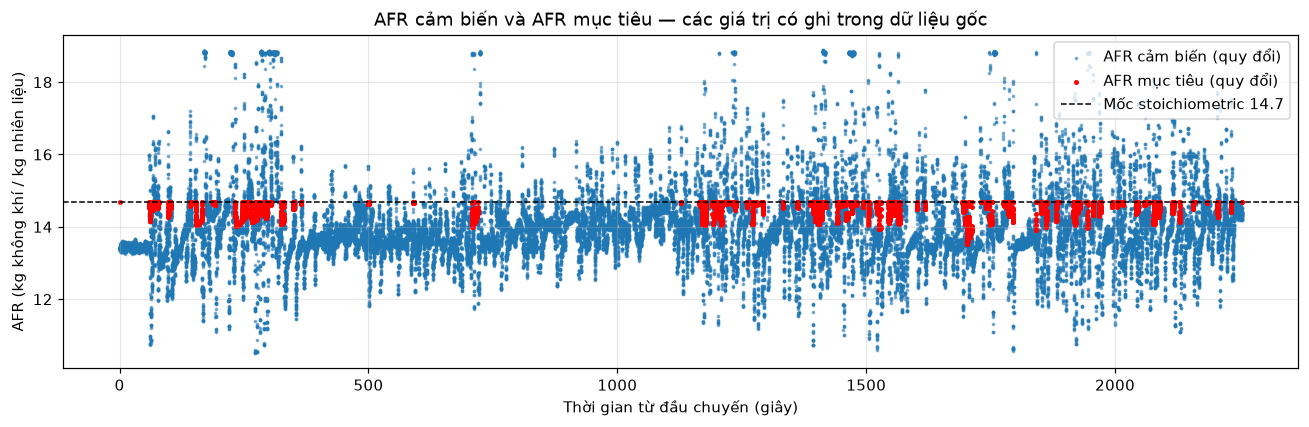

In [6]:
plt.figure(figsize=(12, 4))
plt.scatter(df_work["elapsed_s"], raw_to_afr(df_work["LambdaSensor1"]),
            s=2, alpha=0.5, label="AFR cảm biến (quy đổi)")
plt.scatter(df_work["elapsed_s"], raw_to_afr(df_work["TargetAFR"]),
            s=5, color="red", label="AFR mục tiêu (quy đổi)")
plt.axhline(STOICH_AFR, color="black", linestyle="--", linewidth=1,
            label=f"Mốc stoichiometric {STOICH_AFR:g}")
plt.xlabel("Thời gian từ đầu chuyến (giây)")
plt.ylabel("AFR (kg không khí / kg nhiên liệu)")
plt.title("AFR cảm biến và AFR mục tiêu — các giá trị có ghi trong dữ liệu gốc")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
channels = [
    "RPM", "Load", "BaseFuel",
    "TargetAFR", "LambdaSensor1",
    "CoolantTemp", "ThrottlePosition"
]

records = []

for col in channels:
    observed_time = df_work.loc[
        df_work[col].notna(), "elapsed_s"
    ]
    gaps = observed_time.diff().dropna()

    records.append({
        "channel": col,
        "observed_count": len(observed_time),
        "missing_pct": df_work[col].isna().mean() * 100,
        "median_gap_s": gaps.median(),
        "p95_gap_s": gaps.quantile(0.95),
        "max_gap_s": gaps.max(),
    })

channel_report = pd.DataFrame(records)
channel_report.round(3)

,channel,observed_count,missing_pct,median_gap_s,p95_gap_s,max_gap_s
0,RPM,60088,12.194,0.031,0.078,1.593
1,Load,52932,22.651,0.032,0.094,1.593
2,BaseFuel,50200,26.644,0.032,0.094,6.046
3,TargetAFR,3836,94.395,0.047,0.484,408.218
4,LambdaSensor1,58487,14.534,0.031,0.078,1.593
5,CoolantTemp,19151,72.015,0.047,0.563,13.343
6,ThrottlePosition,27996,59.090,0.046,0.235,13.140


In [8]:
check_columns = [
    "RPM", "Load", "BaseFuel",
    "TargetAFR", "LambdaSensor1",
    "AirTemp", "CoolantTemp", "BatteryVoltage"
]

df_work[check_columns].describe(
    percentiles=[0.01, 0.5, 0.99]
).T.round(2)

,count,mean,std,min,1%,50%,99%,max
RPM,60088.0,1866.93,671.13,660.0,964.0,1606.0,3783.0,6308.0
Load,52932.0,410.58,166.61,182.0,212.0,339.0,896.0,962.0
BaseFuel,50200.0,418.51,104.33,282.0,291.0,357.0,668.0,782.0
TargetAFR,3836.0,978.93,16.50,920.0,933.0,981.0,1000.0,1000.0
LambdaSensor1,58487.0,952.50,69.55,715.0,808.0,943.0,1280.0,1285.0
AirTemp,20060.0,3258.73,71.21,3090.0,3093.0,3274.0,3354.0,3357.0
CoolantTemp,19151.0,3529.62,68.36,3396.0,3398.0,3550.0,3615.0,3619.0
BatteryVoltage,55468.0,12985.39,143.76,12058.0,12637.0,12997.0,13231.0,13309.0


In [9]:
afr_check = df1[["TargetAFR", "LambdaSensor1", "AFRDifference"]].dropna().copy()
afr_check["difference_calculated_raw"] = (
    afr_check["TargetAFR"] - afr_check["LambdaSensor1"]
)
afr_check["matches_raw"] = (
    afr_check["difference_calculated_raw"] == afr_check["AFRDifference"]
)
afr_check["target_afr"] = raw_to_afr(afr_check["TargetAFR"])
afr_check["measured_afr"] = raw_to_afr(afr_check["LambdaSensor1"])
afr_check["target_minus_sensor_afr"] = (
    afr_check["target_afr"] - afr_check["measured_afr"]
)
afr_check[["target_afr", "measured_afr", "target_minus_sensor_afr", "matches_raw"]].head(10)

,target_afr,measured_afr,target_minus_sensor_afr,matches_raw
0,14.7000,13.4064,1.2936,True
2374,14.7000,15.9789,-1.2789,True
2377,14.6559,15.9789,-1.3230,True
2378,14.6118,15.9936,-1.3818,True
2383,14.5530,15.9642,-1.4112,True
2384,14.5236,15.8466,-1.3230,True
2385,14.5089,15.6114,-1.1025,True
2386,14.4942,15.6849,-1.1907,True
2387,14.4795,15.6702,-1.1907,True
2388,14.4501,15.6114,-1.1613,True


## 9. Bảng Target AFR và AFR cảm biến theo RPM × Load

Hình tham khảo là **bảng AFR mục tiêu (Target AFR)**. Bản đồ chính ở đây dùng RPM
làm cột, Load làm hàng, mỗi ô là trung vị AFR mục tiêu tại vùng đó. Bảng cảm biến
cho biết AFR đo được; bảng sai lệch giúp đối chiếu. `BaseFuel` là một kênh khác,
không còn là đại lượng trong các ô bản đồ AFR.

Theo giả thiết đã thống nhất cho bộ log này:

$$\lambda=\frac{raw}{1000},\qquad AFR=\frac{raw}{1000}\times14.7.$$

Ví dụ 1000 → 1,000 lambda → 14,7 AFR; 920 → 0,920 lambda → 13,524 AFR.
Hệ số được khai báo một lần ở cell đầu. Các cột gốc được bảo toàn; bổ sung cột
`target_lambda`, `measured_lambda`, `target_afr`, `measured_afr`.
Mốc 14,7 chỉ là mốc tham chiếu; không ép toàn bộ `TargetAFR` về 14,7.

Quy trình: kiểm tra → gộp thời gian trùng → giữ giá trị trước có giới hạn
→ lưới đều → quy đổi AFR → chia vùng → thống kê và vẽ bảng có số trong ô.
Ô trống có thể là kênh chưa cập nhật: đây vẫn là giả thiết tái dựng chưa xác nhận
cho định dạng xuất log. Không nội suy các vùng còn thiếu, không sao chép số từ hình mẫu.

Nguồn về quan hệ lambda–AFR: [Haltech CAN Units](https://support.haltech.com/portal/en/kb/articles/haltech-can-protocol-specification).
Đây là bảng mô tả một chuyến dưới các giả thiết trên, chưa phải bảng hiệu chỉnh đã kiểm chứng.

In [10]:
import numpy as np
from IPython.display import display

# Các lựa chọn thực hành, có thể chỉnh rồi chạy lại từ cell này trở xuống.
SAMPLE_PERIOD_S = 0.1
SEGMENT_GAP_S = 2.0
MAX_AGE_S = {
    "RPM": 0.25, "Load": 0.25,
    "LambdaSensor1": 0.25, "TargetAFR": 2.0,
    "CoolantTemp": 2.0, "ThrottlePosition": 0.25,
}
RPM_BIN_WIDTH = 500
LOAD_BIN_WIDTH = 50  # Giữ số đo Load gốc.
MIN_GRID_SAMPLES = 30
MIN_CHANNEL_UPDATES = 5
AFR_COLOR_MIN, AFR_COLOR_MAX = 10.0, 20.0
CORE = ["RPM", "Load"]  # Không buộc có BaseFuel để lập bản đồ AFR.
MAP_CHANNELS = list(MAX_AGE_S)
assert STOICH_AFR > 0 and LAMBDA_RAW_SCALE > 0
assert SAMPLE_PERIOD_S > 0 and SEGMENT_GAP_S > 0
assert RPM_BIN_WIDTH > 0 and LOAD_BIN_WIDTH > 0
assert MIN_GRID_SAMPLES >= 1 and MIN_CHANNEL_UPDATES >= 1
assert AFR_COLOR_MIN < AFR_COLOR_MAX
assert all(value >= 0 for value in MAX_AGE_S.values())
np.testing.assert_allclose(raw_to_afr(1000.0), 14.7)
np.testing.assert_allclose(raw_to_afr(920.0), 13.524)

display(pd.Series(MAX_AGE_S, name="max_age_s").to_frame())
print(f"AFR = raw / {LAMBDA_RAW_SCALE:g} × {STOICH_AFR:g}")

,max_age_s
RPM,0.25
Load,0.25
LambdaSensor1,0.25
TargetAFR,2.00
CoolantTemp,2.00
ThrottlePosition,0.25


AFR = raw / 1000 × 14.7


### 9.1. Kiểm tra đầu vào và bảo toàn dữ liệu gốc

`df1` được giữ nguyên. `df_raw` bổ sung mã chuyến và thứ tự bản ghi (đánh số từ 0).
Kiểm tra thời gian, số không hữu hạn, lỗi chuyển kiểu và các dòng trùng hoàn toàn.
Nếu thời gian lỗi/đi lùi hoặc số không hợp lệ xuất hiện, dừng để kiểm tra nguồn.

In [11]:
df_raw = df1.copy(deep=True)
df_raw["trip_id"] = file.stem
df_raw["source_row"] = np.arange(len(df_raw))
missing_channels = set(MAP_CHANNELS) - set(df1.columns)
assert not missing_channels, f"Thiếu các kênh: {sorted(missing_channels)}"
assert len(df_raw) > 0, "CSV không có bản ghi."

parsed_time = pd.to_timedelta(df_raw["Time"], errors="coerce")
assert parsed_time.notna().all(), "Có Time không đọc được; kiểm tra trước khi tiếp tục."
assert parsed_time.diff().dropna().ge(pd.Timedelta(0)).all(), (
    "Thời gian đi lùi hoặc qua nửa đêm; cần xử lý trước khi lập bản đồ."
)
elapsed = parsed_time - parsed_time.iloc[0]
numeric = df_raw[MAP_CHANNELS].apply(pd.to_numeric, errors="coerce")
conversion_errors = (df_raw[MAP_CHANNELS].notna() & numeric.isna()).sum()
nonfinite = (numeric.notna() & ~np.isfinite(numeric)).sum()
assert conversion_errors.sum() == 0, conversion_errors.to_dict()
assert nonfinite.sum() == 0, nonfinite.to_dict()

input_quality = pd.DataFrame({
    "raw_dtype": df1[MAP_CHANNELS].dtypes.astype(str),
    "observed_count": numeric.notna().sum(),
    "missing_pct": numeric.isna().mean() * 100,
    "unique_observed": numeric.nunique(),
    "conversion_errors": conversion_errors,
    "nonfinite_values": nonfinite,
})
time_audit = pd.Series({
    "raw_rows": len(df_raw),
    "unique_timestamps": parsed_time.nunique(),
    "extra_rows_at_duplicate_times": parsed_time.duplicated().sum(),
    "fully_duplicate_rows": df1.duplicated().sum(),
    "duration_s": elapsed.iloc[-1].total_seconds(),
    "largest_gap_s": elapsed.diff().dt.total_seconds().max(),
}, name="value")
display(input_quality.round(3), time_audit.to_frame())

,raw_dtype,observed_count,missing_pct,unique_observed,conversion_errors,nonfinite_values
RPM,float64,60088,12.194,2547,0,0
Load,float64,52932,22.651,762,0,0
LambdaSensor1,float64,58487,14.534,545,0,0
TargetAFR,float64,3836,94.395,81,0,0
CoolantTemp,float64,19151,72.015,150,0,0
ThrottlePosition,float64,27996,59.090,456,0,0


,value
raw_rows,68433.000
unique_timestamps,68373.000
extra_rows_at_duplicate_times,60.000
fully_duplicate_rows,0.000
duration_s,2254.906
largest_gap_s,1.593


### 9.2. Các dòng có cùng thời gian

Quy ước trên bảng phân tích: lấy **giá trị không khuyết cuối cùng của mỗi kênh**
tại cùng một mốc, theo thứ tự bản ghi gốc. Bản ghi nguồn vẫn còn trong `df_raw`.
Nếu một kênh có nhiều giá trị khác nhau ở cùng mốc, ghi số trường hợp vào báo cáo.
Bảng sau gộp có thể ghép giá trị từ nhiều dòng cùng thời gian; không khẳng định
chúng là một phép đo đồng thời ở độ phân giải cao hơn log.

In [12]:
event_source = numeric.copy()
event_source["elapsed"] = elapsed
event_source["source_row"] = df_raw["source_row"]
by_time = event_source.groupby("elapsed", sort=True)
duplicate_conflicts = by_time[MAP_CHANNELS].nunique().gt(1).sum().rename(
    "timestamps_with_conflicting_values"
).to_frame()
events = by_time[MAP_CHANNELS].last()
event_sources = by_time["source_row"].agg(["min", "max", "count"])
events["segment_id"] = (
    events.index.to_series().diff().dt.total_seconds().gt(SEGMENT_GAP_S)
    .cumsum().to_numpy()
)
assert len(events) == parsed_time.nunique()
assert events.index.is_unique and events.index.is_monotonic_increasing
display(duplicate_conflicts, event_sources.query("count > 1").head(10))
print("Số đoạn ghi liên tục:", events["segment_id"].nunique())

,timestamps_with_conflicting_values
RPM,44
Load,29
LambdaSensor1,45
TargetAFR,1
CoolantTemp,8
ThrottlePosition,20


,min,max,count
elapsed,,,
0 days 00:03:20.312000,7909,7910,2
0 days 00:05:12.594000,12248,12249,2
0 days 00:05:12.953000,12260,12261,2
0 days 00:05:13.125000,12266,12267,2
0 days 00:05:13.453000,12280,12281,2
0 days 00:08:42.297000,20305,20306,2
0 days 00:12:51.750000,27564,27565,2
0 days 00:12:52.062000,27574,27575,2
0 days 00:12:52.140000,27577,27578,2


Số đoạn ghi liên tục: 1


### 9.3. Xử lý khuyết và tạo lưới thời gian 0,1 giây

Tại mốc $t$, tìm lần ghi không khuyết gần nhất $t_k \leq t$ cho từng kênh:

$$x^*(t)=x(t_k)\quad\text{khi}\quad 0\leq t-t_k\leq A_x.$$

$A_x$ là `MAX_AGE_S` của kênh. Ngoài giới hạn này giữ `NaN`. Không lấy dữ liệu
từ tương lai, không truyền giá trị qua ranh giới đoạn ghi, không dùng trung bình
để điền khuyết. Cột `__age_s` lưu độ cũ; `__source_elapsed_s` lưu thời điểm nguồn;
`__carried` đánh dấu giá trị được mang từ mốc trước đến mốc lưới.

Lưới đều giúp vùng có nhiều bản ghi cập nhật không tự động được tính trọng số lớn
hơn vùng có cùng thời lượng nhưng ít bản ghi. Số mốc lưới không phải số phép đo độc lập.
Thay đổi các giả thiết ở phần cài đặt rồi chạy lại các cell phía dưới để so sánh.

In [13]:
step = pd.to_timedelta(SAMPLE_PERIOD_S, unit="s")
parts = []
for segment_id, segment in events.groupby("segment_id", sort=True):
    grid = pd.timedelta_range(
        start=segment.index.min().ceil(step),
        end=segment.index.max().floor(step), freq=step,
        name="elapsed",
    )
    if len(grid) == 0:
        continue
    union_index = segment.index.union(grid).sort_values()
    history = segment[MAP_CHANNELS].reindex(union_index).ffill()
    aligned_part = pd.DataFrame(index=grid)
    aligned_part["segment_id"] = segment_id
    grid_seconds = pd.Series(grid.total_seconds(), index=grid)
    for channel, max_age in MAX_AGE_S.items():
        recorded_at = pd.Series(
            segment.index.total_seconds(), index=segment.index
        ).where(segment[channel].notna())
        last_recorded = recorded_at.reindex(union_index).ffill().reindex(grid)
        age = grid_seconds - last_recorded
        fresh = age.ge(-1e-9) & age.le(max_age + 1e-9)
        aligned_part[channel] = history[channel].reindex(grid).where(fresh)
        aligned_part[channel + "__age_s"] = age
        aligned_part[channel + "__source_elapsed_s"] = last_recorded
        aligned_part[channel + "__carried"] = (
            aligned_part[channel].notna() & age.gt(1e-9)
        )
    parts.append(aligned_part)

assert parts, "Không có đoạn ghi đủ dài cho chu kỳ lấy mẫu đã chọn."
df_aligned = pd.concat(parts).sort_index()
df_aligned["elapsed_s"] = df_aligned.index.total_seconds()
df_aligned["trip_id"] = file.stem

alignment_report = pd.DataFrame({
    "raw_missing_pct": numeric.isna().mean() * 100,
    "grid_missing_pct": df_aligned[MAP_CHANNELS].isna().mean() * 100,
    "grid_carried_pct": pd.Series({
        c: df_aligned[c + "__carried"].mean() * 100 for c in MAP_CHANNELS
    }),
    "max_allowed_age_s": pd.Series(MAX_AGE_S),
})
display(alignment_report.round(3))
print("Tỷ lệ thiếu gốc và lưới dùng hai tập mốc thời gian khác nhau.")
display(df_aligned[["elapsed_s", "RPM", "RPM__age_s", "Load", "TargetAFR", "LambdaSensor1"]].head(12))

,raw_missing_pct,grid_missing_pct,grid_carried_pct,max_allowed_age_s
RPM,12.194,0.111,91.002,0.25
Load,22.651,0.701,91.361,0.25
LambdaSensor1,14.534,0.111,91.135,0.25
TargetAFR,94.395,78.319,21.069,2.00
CoolantTemp,72.015,4.674,92.412,2.00
ThrottlePosition,59.090,27.410,68.594,0.25


Tỷ lệ thiếu gốc và lưới dùng hai tập mốc thời gian khác nhau.


,elapsed_s,RPM,RPM__age_s,Load,TargetAFR,LambdaSensor1
elapsed,,,,,,
0 days 00:00:00,0.0,1164.0,0.000,360.0,1000.0,912.0
0 days 00:00:00.100000,0.1,1168.0,0.038,361.0,1000.0,914.0
0 days 00:00:00.200000,0.2,1169.0,0.044,358.0,1000.0,914.0
0 days 00:00:00.300000,0.3,1176.0,0.003,356.0,1000.0,908.0
0 days 00:00:00.400000,0.4,1151.0,0.025,361.0,1000.0,910.0
0 days 00:00:00.500000,0.5,1158.0,0.000,361.0,1000.0,912.0
0 days 00:00:00.600000,0.6,1161.0,0.053,361.0,1000.0,910.0
0 days 00:00:00.700000,0.7,1161.0,0.013,359.0,1000.0,908.0
0 days 00:00:00.800000,0.8,1133.0,0.003,362.0,1000.0,911.0


### 9.4. Quy đổi AFR và kiểm chứng dữ liệu đồng bộ

Chỉ giữ vị trí vận hành có đủ RPM và Load, RPM > 0 và Load ≥ 0. Đối với từng bảng,
chỉ dùng kênh AFR dương và còn trong giới hạn độ cũ; không buộc kênh kia phải có
dữ liệu. Vì vậy bảng mục tiêu và bảng cảm biến có độ phủ khác nhau. Không loại số
đo chỉ vì khác 14,7; không gán giá trị thiếu thành 14,7.

Quy ước sai lệch mới: **AFR cảm biến − AFR mục tiêu**. Giá trị dương là cảm biến
cao hơn mục tiêu. Cột `AFRDifference` gốc có chiều ngược lại (mục tiêu − cảm biến),
nên khi đổi đơn vị để đối chiếu phải đổi cả dấu.

,value
grid_rows,22550
missing_position_rows,158
complete_position_outside_basic_range,0
valid_position_rows,22392
valid_target_rows,4874
valid_measured_rows,22392
valid_paired_rows,4874


,TargetAFR,target_afr,LambdaSensor1,measured_afr,afr_error
elapsed,,,,,
0 days 00:00:00,1000.0,14.7,912.0,13.4064,-1.2936
0 days 00:00:00.100000,1000.0,14.7,914.0,13.4358,-1.2642
0 days 00:00:00.200000,1000.0,14.7,914.0,13.4358,-1.2642
0 days 00:00:00.300000,1000.0,14.7,908.0,13.3476,-1.3524
0 days 00:00:00.400000,1000.0,14.7,910.0,13.3770,-1.3230
0 days 00:00:00.500000,1000.0,14.7,912.0,13.4064,-1.2936
0 days 00:00:00.600000,1000.0,14.7,910.0,13.3770,-1.3230
0 days 00:00:00.700000,1000.0,14.7,908.0,13.3476,-1.3524
0 days 00:00:00.800000,1000.0,14.7,911.0,13.3917,-1.3083


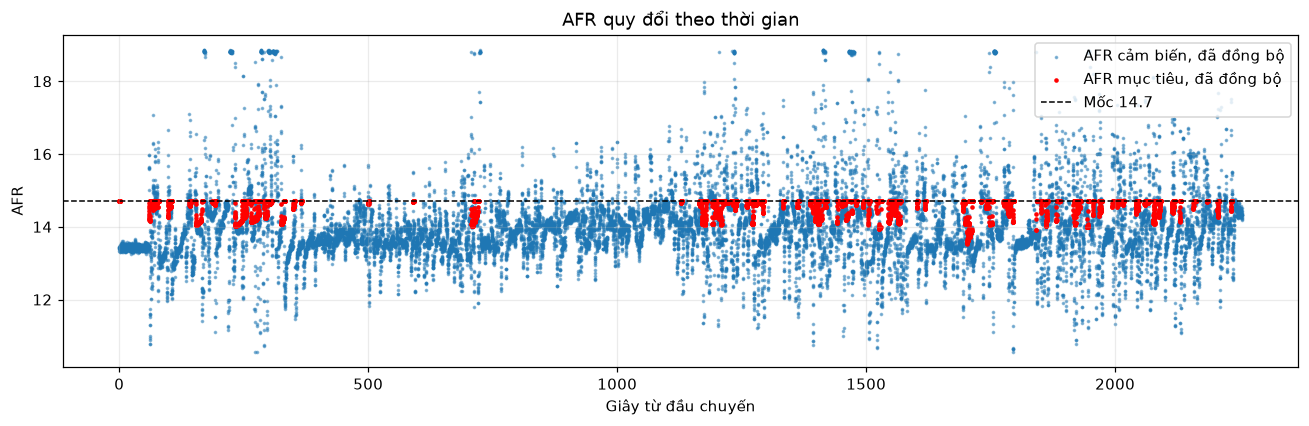

In [14]:
for channel, max_age in MAX_AGE_S.items():
    valid = df_aligned[channel].notna()
    ages = df_aligned.loc[valid, channel + "__age_s"]
    assert ages.ge(-1e-9).all() and ages.le(max_age + 1e-9).all()
    source_time = df_aligned.loc[valid, channel + "__source_elapsed_s"]
    lookup = pd.Series(events[channel].to_numpy(), index=events.index.total_seconds())
    expected = lookup.reindex(source_time.to_numpy()).to_numpy()
    np.testing.assert_allclose(df_aligned.loc[valid, channel].to_numpy(),
                               expected, rtol=0, atol=0)
    source_segments = pd.Series(
        events["segment_id"].to_numpy(), index=events.index.total_seconds()
    ).reindex(source_time.to_numpy()).to_numpy()
    assert (source_segments == df_aligned.loc[valid, "segment_id"].to_numpy()).all()

df_aligned["target_lambda"] = df_aligned["TargetAFR"] / LAMBDA_RAW_SCALE
df_aligned["measured_lambda"] = df_aligned["LambdaSensor1"] / LAMBDA_RAW_SCALE
df_aligned["target_afr"] = raw_to_afr(df_aligned["TargetAFR"])
df_aligned["measured_afr"] = raw_to_afr(df_aligned["LambdaSensor1"])
df_aligned["afr_error"] = df_aligned["measured_afr"] - df_aligned["target_afr"]
for raw_channel, afr_channel in [("TargetAFR", "target_afr"), ("LambdaSensor1", "measured_afr")]:
    assert df_aligned[raw_channel].isna().equals(df_aligned[afr_channel].isna())
    np.testing.assert_allclose(
        df_aligned[afr_channel].dropna(),
        df_aligned.loc[df_aligned[afr_channel].notna(), raw_channel] / LAMBDA_RAW_SCALE * STOICH_AFR,
    )

complete = df_aligned[CORE].notna().all(axis=1)
basic_range = df_aligned["RPM"].gt(0) & df_aligned["Load"].ge(0)
df_aligned["usable_position"] = complete & basic_range
df_aligned["usable_target_afr"] = (
    df_aligned["usable_position"] & df_aligned["target_afr"].gt(0)
)
df_aligned["usable_measured_afr"] = (
    df_aligned["usable_position"] & df_aligned["measured_afr"].gt(0)
)
map_points = df_aligned.loc[df_aligned["usable_position"]].copy()
assert not map_points.empty, "Không có vị trí RPM–Load hợp lệ."
for channel, raw_channel, flag in [
    ("target_afr", "TargetAFR", "usable_target_afr"),
    ("measured_afr", "LambdaSensor1", "usable_measured_afr"),
]:
    map_points[channel] = map_points[channel].where(map_points[flag])
    map_points[channel + "__source_s"] = map_points[raw_channel + "__source_elapsed_s"].where(
        map_points[channel].notna()
    )
paired = map_points[["target_afr", "measured_afr"]].notna().all(axis=1)
map_points["afr_error"] = (map_points["measured_afr"] - map_points["target_afr"]).where(paired)
map_points["paired_target_source_s"] = map_points["target_afr__source_s"].where(paired)
map_points["paired_measured_source_s"] = map_points["measured_afr__source_s"].where(paired)

selection_report = pd.Series({
    "grid_rows": len(df_aligned),
    "missing_position_rows": (~complete).sum(),
    "complete_position_outside_basic_range": (complete & ~basic_range).sum(),
    "valid_position_rows": len(map_points),
    "valid_target_rows": map_points["target_afr"].notna().sum(),
    "valid_measured_rows": map_points["measured_afr"].notna().sum(),
    "valid_paired_rows": paired.sum(),
}, name="value")
display(selection_report.to_frame())
display(df_aligned[["TargetAFR", "target_afr", "LambdaSensor1", "measured_afr", "afr_error"]].head(12).round(4))

fig_afr_time, ax = plt.subplots(figsize=(12, 4))
ax.scatter(df_aligned["elapsed_s"], df_aligned["measured_afr"], s=2, alpha=0.45,
           label="AFR cảm biến, đã đồng bộ")
ax.scatter(df_aligned["elapsed_s"], df_aligned["target_afr"], s=4, color="red",
           label="AFR mục tiêu, đã đồng bộ")
ax.axhline(STOICH_AFR, color="black", linestyle="--", linewidth=1,
           label=f"Mốc {STOICH_AFR:g}")
ax.set(xlabel="Giây từ đầu chuyến", ylabel="AFR", title="AFR quy đổi theo thời gian")
ax.grid(alpha=0.25)
ax.legend()
fig_afr_time.tight_layout()
plt.show()

### 9.5. Thống kê AFR theo vùng RPM × Load

Khoảng RPM rộng 500, khoảng Load rộng 50, đóng trái và mở phải `[a, b)`.
Mỗi ô của bảng mục tiêu là:

$$T_{ij}=\operatorname{median}\{AFR_{target}(t):t\in B_{ij}\}.$$

Tương tự, $M_{ij}$ là trung vị AFR cảm biến. Sai lệch được tính trên **các cặp tại
cùng mốc** rồi lấy trung vị, không lấy hiệu của hai trung vị có tập mẫu khác nhau.
Mỗi bảng có số mốc và số thời điểm nguồn riêng. Chỉ hiển thị ô có ≥30 mốc lưới
và ≥5 thời điểm ghi nguồn của kênh đó. Đây là bộ lọc thưa để thực hành, không phải
kiểm định độ tin cậy. Các mốc lưới và thời điểm nguồn không bảo đảm độc lập.

In [15]:
rpm_edges = np.arange(
    np.floor(map_points["RPM"].min() / RPM_BIN_WIDTH) * RPM_BIN_WIDTH,
    (np.floor(map_points["RPM"].max() / RPM_BIN_WIDTH) + 2) * RPM_BIN_WIDTH,
    RPM_BIN_WIDTH,
)
load_edges = np.arange(
    np.floor(map_points["Load"].min() / LOAD_BIN_WIDTH) * LOAD_BIN_WIDTH,
    (np.floor(map_points["Load"].max() / LOAD_BIN_WIDTH) + 2) * LOAD_BIN_WIDTH,
    LOAD_BIN_WIDTH,
)
map_points["rpm_bin"] = pd.cut(map_points["RPM"], rpm_edges, right=False)
map_points["load_bin"] = pd.cut(map_points["Load"], load_edges, right=False)
assert map_points[["rpm_bin", "load_bin"]].notna().all().all()

cell_stats = map_points.groupby(["load_bin", "rpm_bin"], observed=True).agg(
    n_grid=("RPM", "size"),
    n_target=("target_afr", "count"),
    n_target_updates=("target_afr__source_s", "nunique"),
    target_afr_median=("target_afr", "median"),
    target_afr_q25=("target_afr", lambda x: x.quantile(0.25)),
    target_afr_q75=("target_afr", lambda x: x.quantile(0.75)),
    n_measured=("measured_afr", "count"),
    n_measured_updates=("measured_afr__source_s", "nunique"),
    measured_afr_median=("measured_afr", "median"),
    measured_afr_q25=("measured_afr", lambda x: x.quantile(0.25)),
    measured_afr_q75=("measured_afr", lambda x: x.quantile(0.75)),
    n_paired=("afr_error", "count"),
    n_paired_target_updates=("paired_target_source_s", "nunique"),
    n_paired_measured_updates=("paired_measured_source_s", "nunique"),
    afr_error_median=("afr_error", "median"),
)
for prefix in ["target", "measured"]:
    cell_stats[prefix + "_represented_time_s"] = cell_stats["n_" + prefix] * SAMPLE_PERIOD_S
    cell_stats[prefix + "_afr_iqr"] = (
        cell_stats[prefix + "_afr_q75"] - cell_stats[prefix + "_afr_q25"]
    )
    cell_stats[prefix + "_supported"] = (
        cell_stats["n_" + prefix].ge(MIN_GRID_SAMPLES)
        & cell_stats["n_" + prefix + "_updates"].ge(MIN_CHANNEL_UPDATES)
    )
cell_stats["paired_supported"] = (
    cell_stats["n_paired"].ge(MIN_GRID_SAMPLES)
    & cell_stats["n_paired_target_updates"].ge(MIN_CHANNEL_UPDATES)
    & cell_stats["n_paired_measured_updates"].ge(MIN_CHANNEL_UPDATES)
)
rpm_intervals = pd.IntervalIndex.from_breaks(rpm_edges, closed="left")
load_intervals = pd.IntervalIndex.from_breaks(load_edges, closed="left")

def map_matrix(column):
    return cell_stats[column].unstack("rpm_bin").reindex(
        index=load_intervals, columns=rpm_intervals
    )

coverage_map = map_matrix("n_grid").fillna(0).astype(int)
target_count_map = map_matrix("n_target").fillna(0).astype(int)
measured_count_map = map_matrix("n_measured").fillna(0).astype(int)
paired_count_map = map_matrix("n_paired").fillna(0).astype(int)
target_support_map = map_matrix("target_supported").eq(True)
measured_support_map = map_matrix("measured_supported").eq(True)
paired_support_map = map_matrix("paired_supported").eq(True)
target_afr_map_all = map_matrix("target_afr_median")
measured_afr_map_all = map_matrix("measured_afr_median")
target_afr_map = target_afr_map_all.where(target_support_map)
measured_afr_map = measured_afr_map_all.where(measured_support_map)
afr_error_map = map_matrix("afr_error_median").where(paired_support_map)

assert coverage_map.to_numpy().sum() == len(map_points)
assert target_count_map.to_numpy().sum() == map_points["target_afr"].notna().sum()
assert measured_count_map.to_numpy().sum() == map_points["measured_afr"].notna().sum()
assert paired_count_map.to_numpy().sum() == map_points["afr_error"].notna().sum()
assert target_afr_map.notna().equals(target_support_map)
assert measured_afr_map.notna().equals(measured_support_map)
assert afr_error_map.notna().equals(paired_support_map)

map_summary = pd.DataFrame({
    "AFR_table": ["Target AFR", "Measured AFR", "Measured - Target"],
    "valid_grid_rows": [cell_stats.n_target.sum(), cell_stats.n_measured.sum(), cell_stats.n_paired.sum()],
    "observed_cells": [(target_count_map > 0).to_numpy().sum(),
                       (measured_count_map > 0).to_numpy().sum(),
                       (paired_count_map > 0).to_numpy().sum()],
    "displayed_cells": [target_support_map.to_numpy().sum(),
                        measured_support_map.to_numpy().sum(),
                        paired_support_map.to_numpy().sum()],
    "total_cells": coverage_map.size,
})
display(map_summary, cell_stats.sort_values("n_target", ascending=False).head(10).round(3))

,AFR_table,valid_grid_rows,observed_cells,displayed_cells,total_cells
0,Target AFR,4874,120,55,204
1,Measured AFR,22392,123,72,204
2,Measured - Target,4874,120,55,204


n_grid  ...  paired_supported
load_bin       rpm_bin                   ...                  
[600.0, 650.0) [2500.0, 3000.0)     322  ...              True
[850.0, 900.0) [2500.0, 3000.0)     231  ...              True
[200.0, 250.0) [2000.0, 2500.0)    1222  ...              True
               [2500.0, 3000.0)     465  ...              True
[650.0, 700.0) [2000.0, 2500.0)     159  ...              True
[250.0, 300.0) [1500.0, 2000.0)    1765  ...              True
[850.0, 900.0) [2000.0, 2500.0)     156  ...              True
[650.0, 700.0) [2500.0, 3000.0)     136  ...              True
[600.0, 650.0) [3000.0, 3500.0)     144  ...              True
[800.0, 850.0) [3000.0, 3500.0)     121  ...              True

[10 rows x 22 columns]

### 9.6. Bảng AFR có số trong ô, theo hình tham khảo

Bảng chính là **Target AFR**, bảng thứ hai là **AFR cảm biến**. Cột là RPM tăng
từ trái sang phải; hàng là Load tăng từ trên xuống dưới, giống bố cục hình mẫu.
Nhãn là khoảng giá trị `[a,b)` chứ không phải điểm đặt chính xác của ECU.
Các ô hiện một chữ số thập phân; bảng CSV giữ độ chính xác đầy đủ.
Hai bảng dùng chung thang màu 10–20 AFR; số được ghi đúng ngay cả khi ngoài thang màu.
Ô xám có dấu “—” là chưa đủ dữ liệu theo quy tắc lọc thưa, không phải AFR bằng 0.

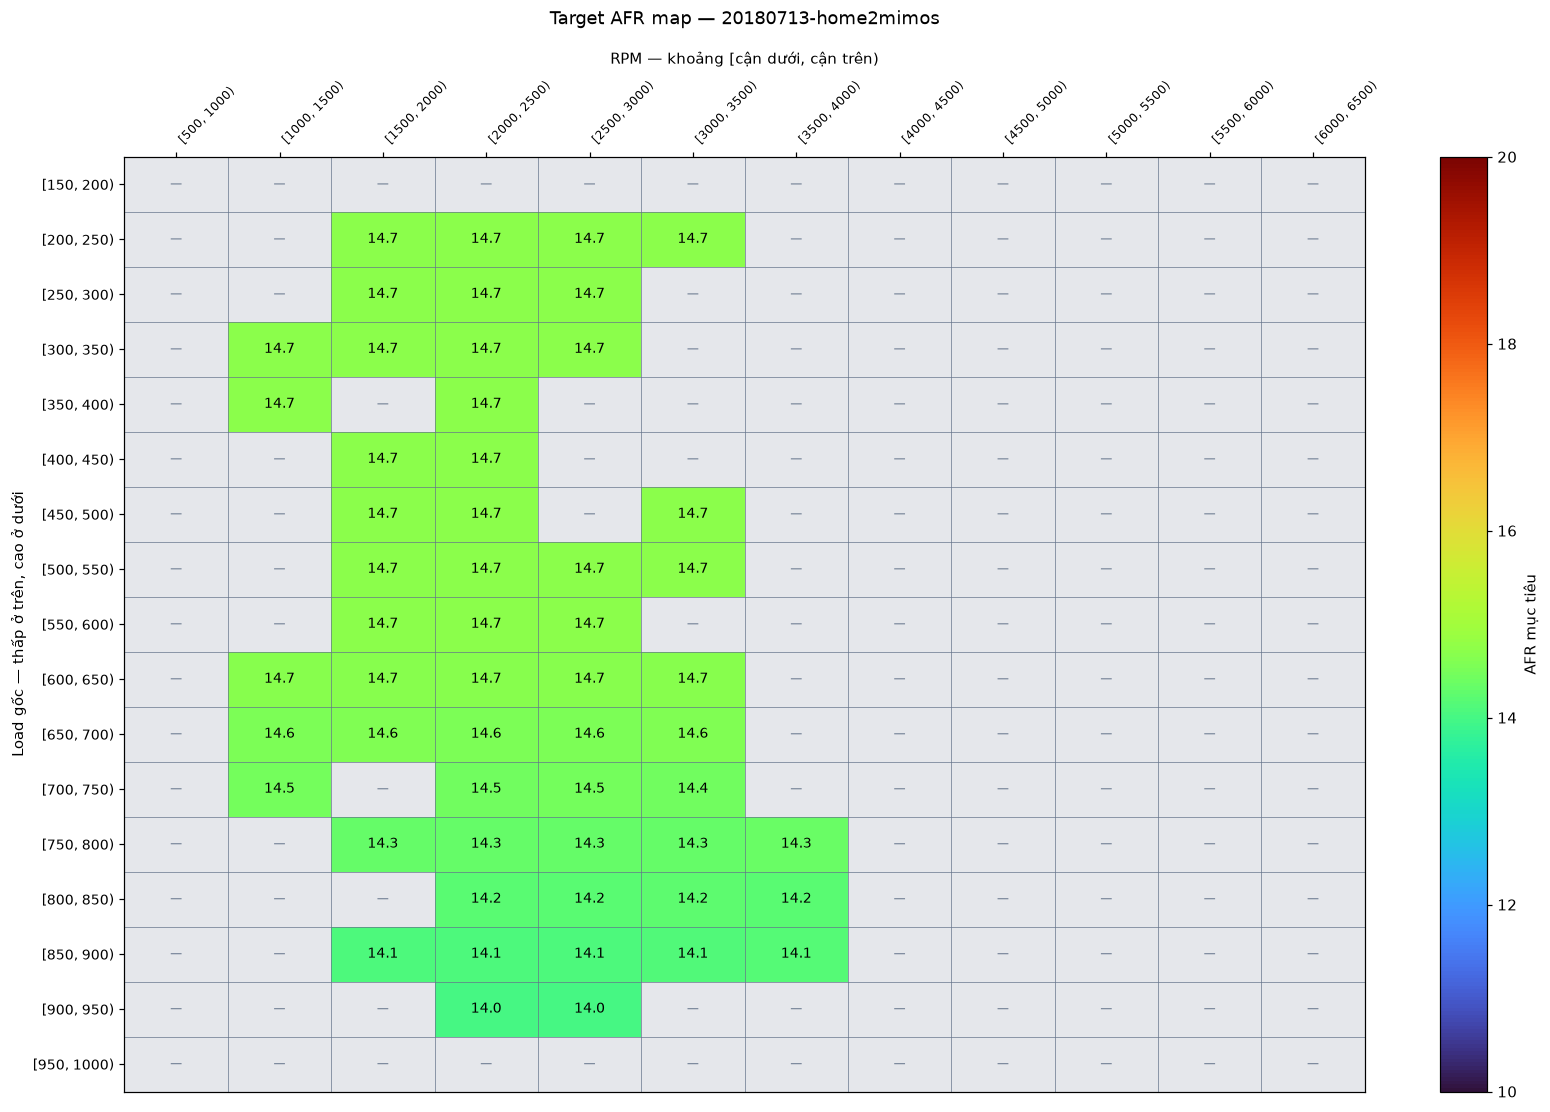

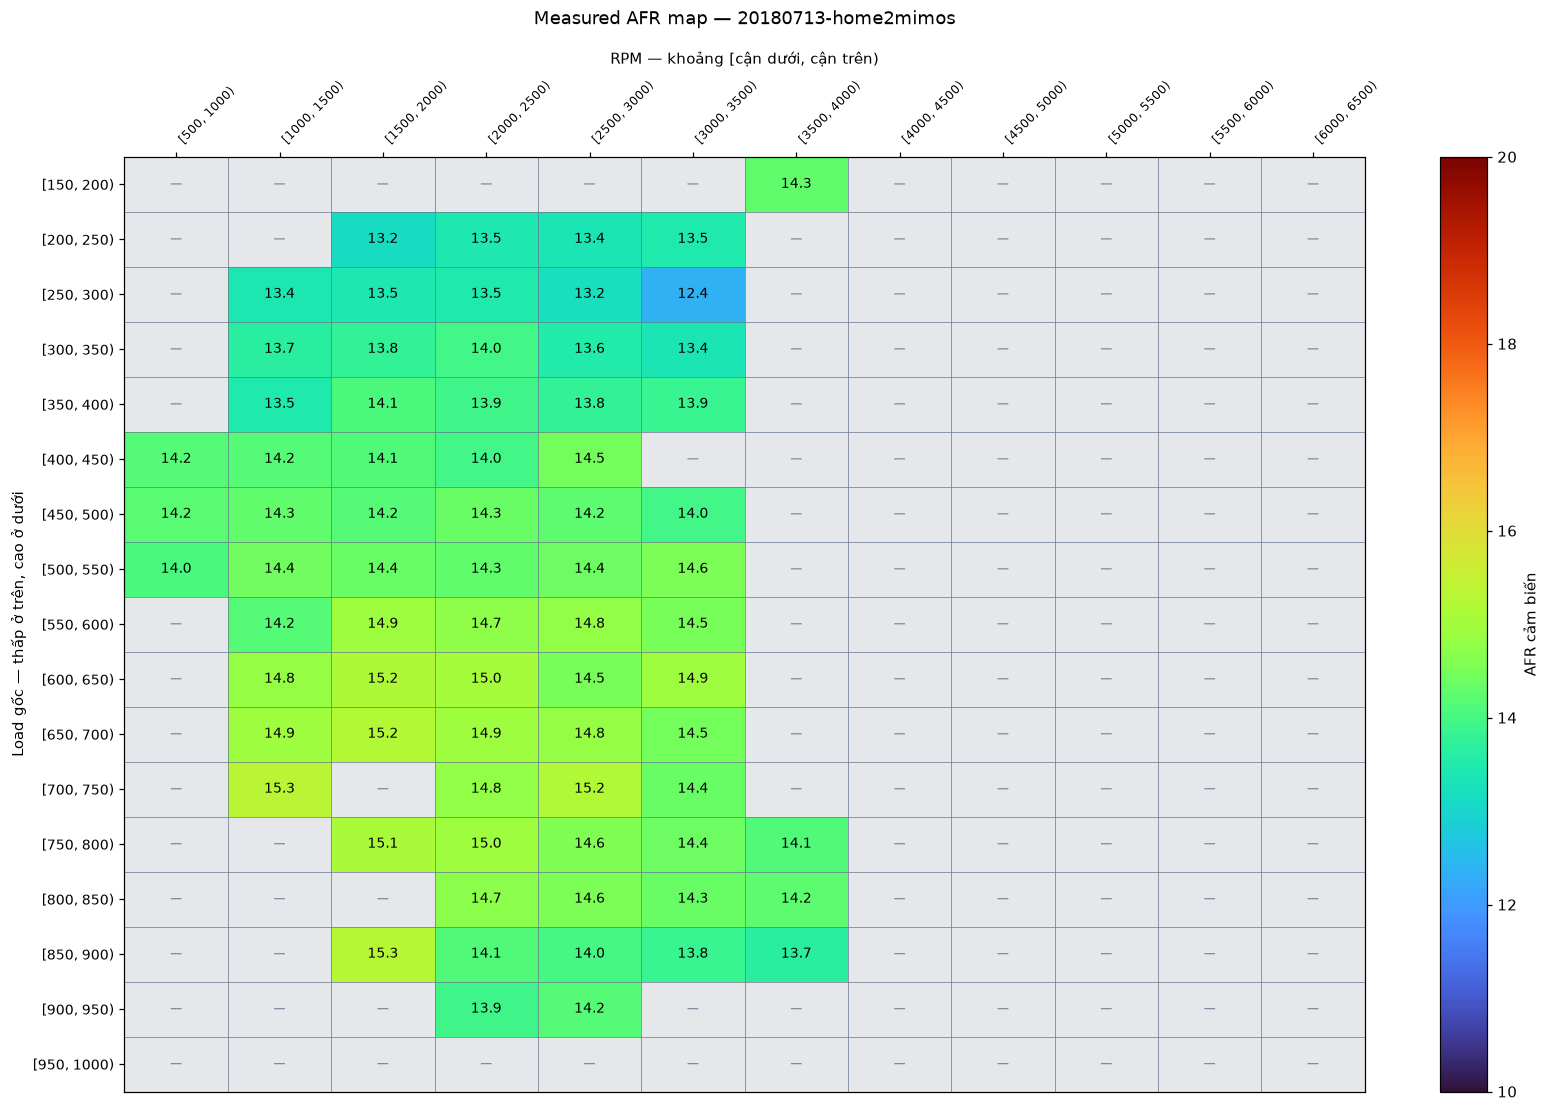

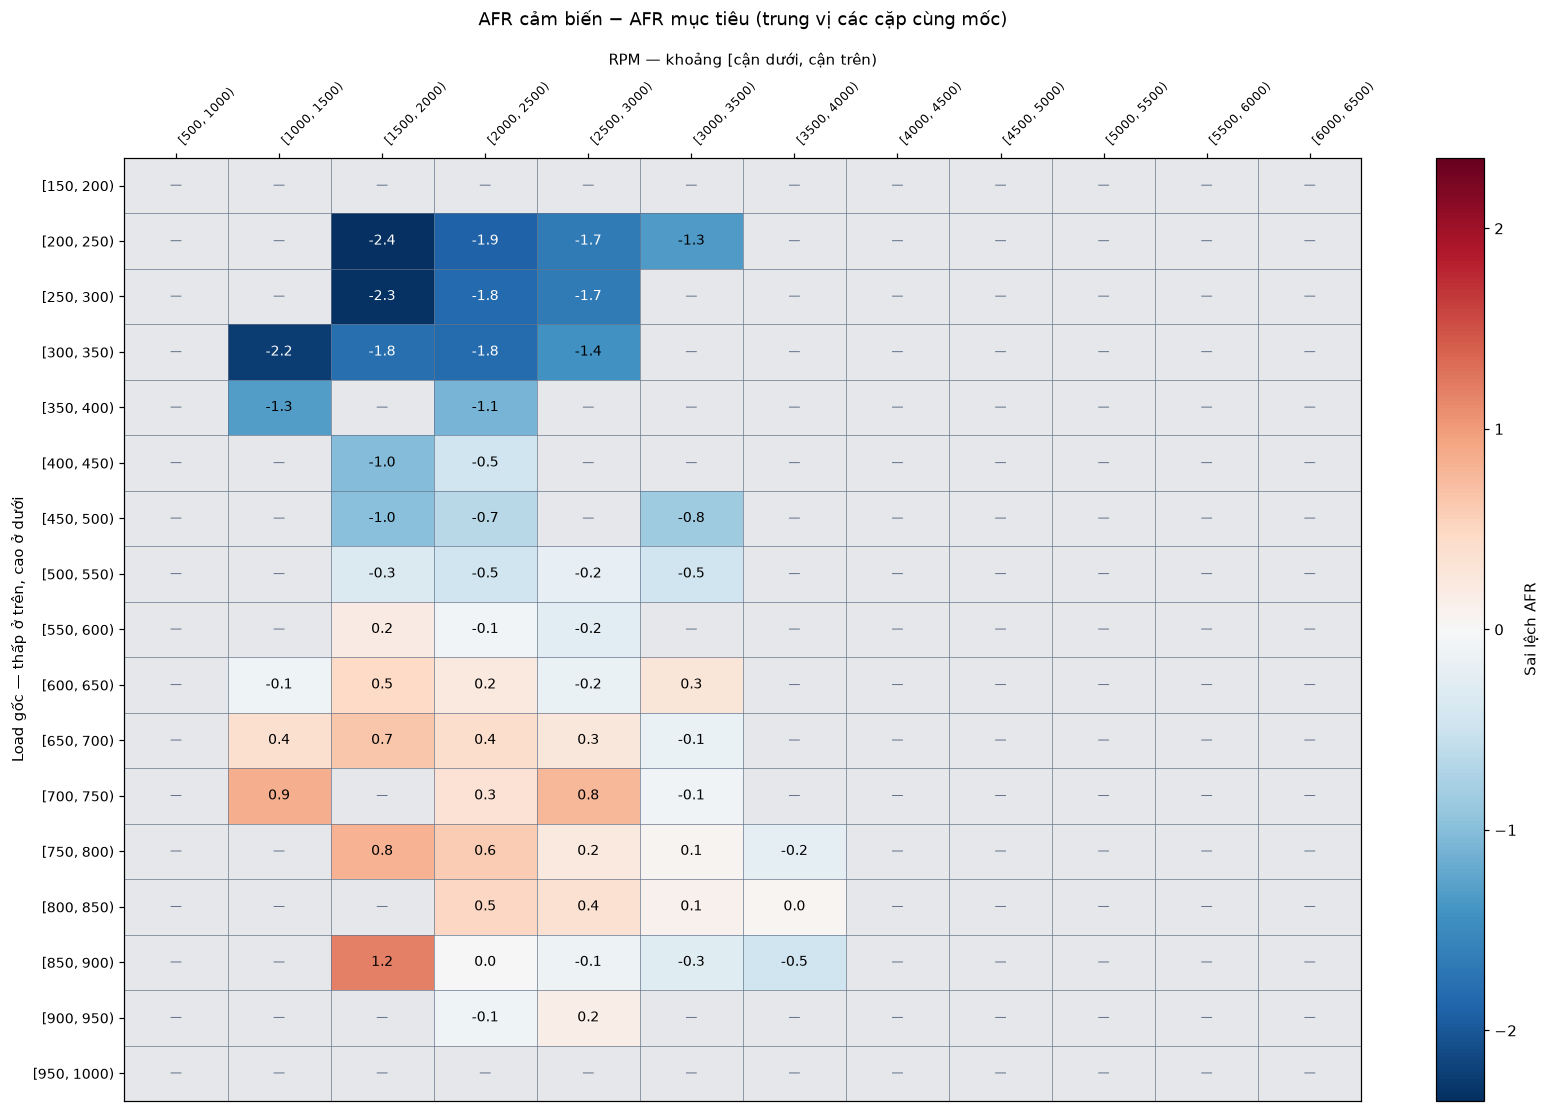

In [16]:
from matplotlib.colors import Normalize, TwoSlopeNorm

def draw_afr_table(ax, matrix, title, *, cmap_name="turbo", norm=None):
    values = matrix.to_numpy(dtype=float)
    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad("#e5e7eb")
    if norm is None:
        norm = Normalize(vmin=AFR_COLOR_MIN, vmax=AFR_COLOR_MAX, clip=True)
    image = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, norm=norm,
                      aspect="auto", origin="upper", interpolation="nearest")
    ax.set_xticks(np.arange(len(matrix.columns)))
    ax.set_xticklabels([f"[{v.left:g}, {v.right:g})" for v in matrix.columns],
                       rotation=45, ha="left", fontsize=8)
    ax.set_yticks(np.arange(len(matrix.index)))
    ax.set_yticklabels([f"[{v.left:g}, {v.right:g})" for v in matrix.index], fontsize=9)
    ax.tick_params(axis="x", top=True, labeltop=True, bottom=False, labelbottom=False)
    ax.xaxis.set_label_position("top")
    ax.set_xlabel("RPM — khoảng [cận dưới, cận trên)", labelpad=10)
    ax.set_ylabel("Load gốc — thấp ở trên, cao ở dưới")
    ax.set_title(title, fontsize=12, pad=18)
    ax.set_xticks(np.arange(-0.5, len(matrix.columns), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(matrix.index), 1), minor=True)
    ax.grid(which="minor", color="#64748b", linewidth=0.45)
    ax.tick_params(which="minor", bottom=False, left=False)
    for row in range(values.shape[0]):
        for col in range(values.shape[1]):
            value = values[row, col]
            if np.isfinite(value):
                red, green, blue, _ = cmap(norm(value))
                luminance = 0.2126 * red + 0.7152 * green + 0.0722 * blue
                color = "black" if luminance > 0.5 else "white"
                ax.text(col, row, f"{value:.1f}", ha="center", va="center",
                        fontsize=9, color=color)
            else:
                ax.text(col, row, "—", ha="center", va="center", fontsize=8, color="#64748b")
    return image

fig_target, ax_target = plt.subplots(figsize=(14, 10), constrained_layout=True)
target_image = draw_afr_table(
    ax_target, target_afr_map, f"Target AFR map — {file.stem}"
)
fig_target.colorbar(target_image, ax=ax_target, label="AFR mục tiêu")
plt.show()

fig_measured, ax_measured = plt.subplots(figsize=(14, 10), constrained_layout=True)
measured_image = draw_afr_table(
    ax_measured, measured_afr_map, f"Measured AFR map — {file.stem}"
)
fig_measured.colorbar(measured_image, ax=ax_measured, label="AFR cảm biến")
plt.show()

finite_error = np.abs(afr_error_map.to_numpy(dtype=float))
error_limit = max(0.5, float(np.nanmax(finite_error))) if np.isfinite(finite_error).any() else 0.5
fig_error, ax_error = plt.subplots(figsize=(14, 10), constrained_layout=True)
error_image = draw_afr_table(
    ax_error, afr_error_map, "AFR cảm biến − AFR mục tiêu (trung vị các cặp cùng mốc)",
    cmap_name="RdBu_r", norm=TwoSlopeNorm(vmin=-error_limit, vcenter=0, vmax=error_limit),
)
fig_error.colorbar(error_image, ax=ax_error, label="Sai lệch AFR")
plt.show()

### 9.7. Đối chiếu với các dòng có dữ liệu gốc

Tính riêng cho từng kênh trên các dòng có đủ RPM, Load và kênh AFR tương ứng,
không điền khuyết, dùng cùng vùng. So sánh ảnh hưởng của tái dựng và lấy mẫu đều.
Hai cách có cách chọn và trọng số khác nhau; chênh lệch không tự chứng minh một
cách đúng hơn. Cột chênh lệch có đơn vị AFR sau quy đổi.

In [17]:
raw_baseline_points = numeric.copy()
raw_baseline_points["target_afr"] = raw_to_afr(raw_baseline_points["TargetAFR"])
raw_baseline_points["measured_afr"] = raw_to_afr(raw_baseline_points["LambdaSensor1"])
comparison = cell_stats.copy()
for prefix, afr_channel in [("target", "target_afr"), ("measured", "measured_afr")]:
    raw_subset = raw_baseline_points[["RPM", "Load", afr_channel]].dropna().copy()
    raw_subset = raw_subset.loc[
        raw_subset["RPM"].gt(0) & raw_subset["Load"].ge(0) & raw_subset[afr_channel].gt(0)
    ]
    raw_subset["rpm_bin"] = pd.cut(raw_subset["RPM"], rpm_edges, right=False)
    raw_subset["load_bin"] = pd.cut(raw_subset["Load"], load_edges, right=False)
    baseline = raw_subset.groupby(["load_bin", "rpm_bin"], observed=True)[afr_channel].agg(
        ["count", "median"]
    ).rename(columns={"count": prefix + "_raw_rows", "median": prefix + "_raw_median"})
    comparison = comparison.join(baseline, how="left")
    comparison[prefix + "_aligned_minus_raw"] = (
        comparison[prefix + "_afr_median"] - comparison[prefix + "_raw_median"]
    )
display(comparison[["n_target", "target_raw_rows", "target_afr_median", "target_raw_median",
                    "target_aligned_minus_raw", "n_measured", "measured_raw_rows",
                    "measured_afr_median", "measured_raw_median", "measured_aligned_minus_raw"]]
        .sort_values("n_target", ascending=False).head(12).round(3))

n_target  ...  measured_aligned_minus_raw
load_bin       rpm_bin                     ...                            
[600.0, 650.0) [2500.0, 3000.0)       240  ...                       0.044
[850.0, 900.0) [2500.0, 3000.0)       231  ...                       0.029
[200.0, 250.0) [2000.0, 2500.0)       201  ...                       0.015
               [2500.0, 3000.0)       177  ...                       0.059
[650.0, 700.0) [2000.0, 2500.0)       159  ...                      -0.044
[250.0, 300.0) [1500.0, 2000.0)       158  ...                       0.015
[850.0, 900.0) [2000.0, 2500.0)       156  ...                       0.015
[650.0, 700.0) [2500.0, 3000.0)       136  ...                       0.022
[600.0, 650.0) [3000.0, 3500.0)       134  ...                       0.000
[800.0, 850.0) [3000.0, 3500.0)       121  ...                      -0.029
[600.0, 650.0) [1500.0, 2000.0)       120  ...                      -0.044
               [2000.0, 2500.0)       113  ...                       0.125

[12 rows x 10 columns]

### 9.8. Độ phủ riêng và kiểm tra công thức sai lệch

Ba bảng đếm có mẫu số riêng: mục tiêu, cảm biến và cặp đủ cả hai kênh.
Số mốc sau giữ giá trị không phải số phép đo độc lập. Bảng Target AFR tái dựng
những mục tiêu đã được ghi, chưa tự đề xuất mục tiêu mới hay hiệu chỉnh BaseFuel.

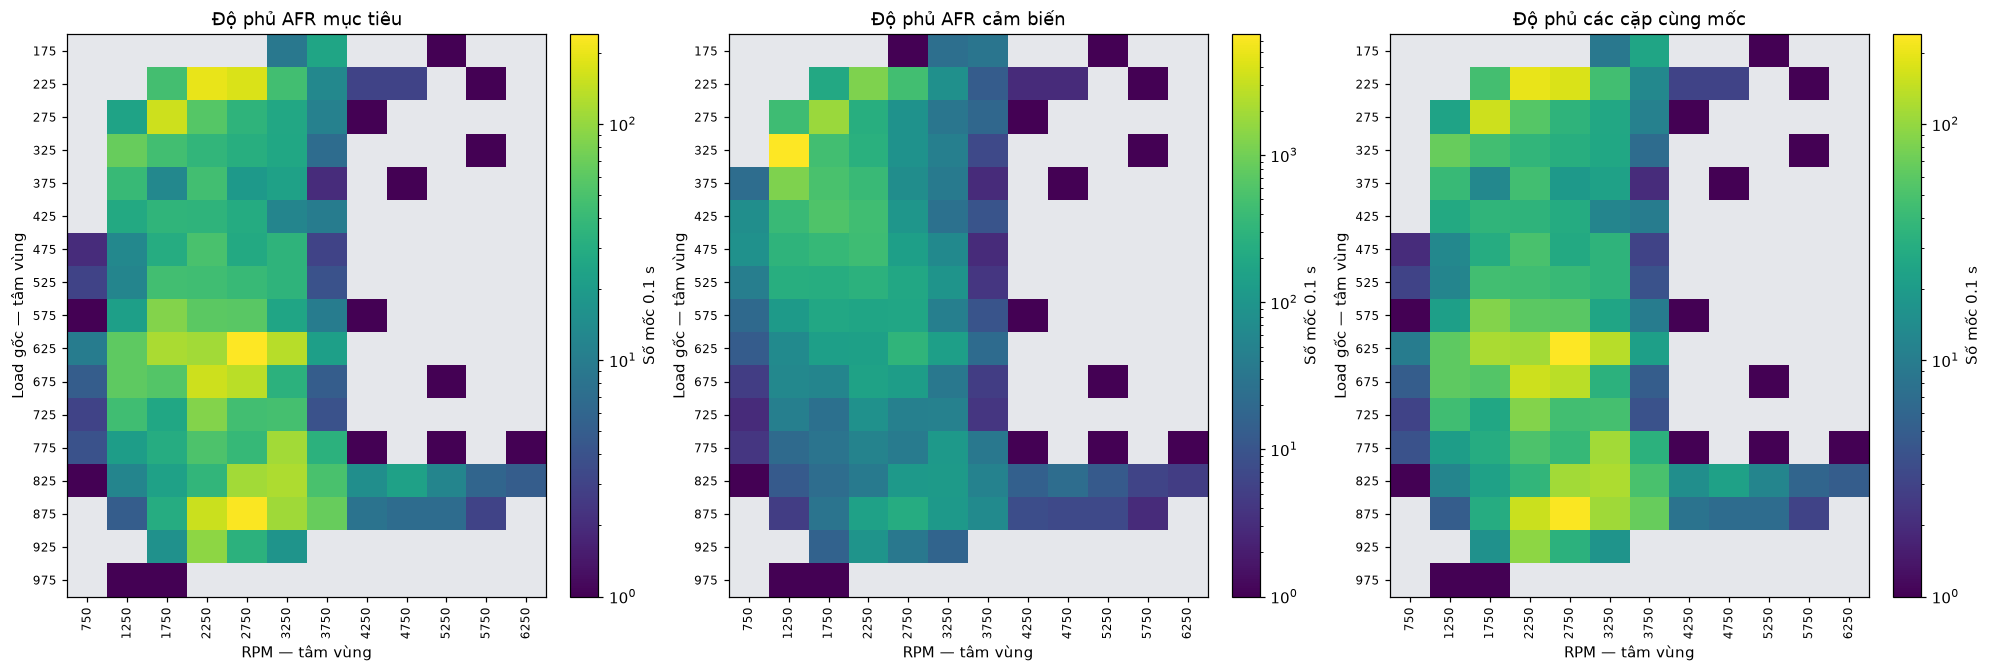

,value
checked_raw_rows,3.438000e+03
matching_rows,3.438000e+03
max_abs_disagreement,4.440892e-15


In [18]:
from matplotlib.colors import LogNorm

fig_coverage, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
for ax, matrix, title in zip(axes,
    [target_count_map, measured_count_map, paired_count_map],
    ["Độ phủ AFR mục tiêu", "Độ phủ AFR cảm biến", "Độ phủ các cặp cùng mốc"]):
    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("#e5e7eb")
    image = ax.imshow(np.ma.masked_where(matrix.to_numpy() == 0, matrix.to_numpy()),
                      origin="upper", aspect="auto", interpolation="nearest", cmap=cmap,
                      norm=LogNorm(vmin=1, vmax=max(2, int(matrix.to_numpy().max()))))
    ax.set_xticks(np.arange(len(rpm_intervals)))
    ax.set_xticklabels([f"{v.mid:g}" for v in rpm_intervals], rotation=90, fontsize=8)
    ax.set_yticks(np.arange(len(load_intervals)))
    ax.set_yticklabels([f"{v.mid:g}" for v in load_intervals], fontsize=8)
    ax.set(xlabel="RPM — tâm vùng", ylabel="Load gốc — tâm vùng", title=title)
    fig_coverage.colorbar(image, ax=ax, label=f"Số mốc {SAMPLE_PERIOD_S:g} s")
plt.show()

# Kiểm tra cả đơn vị lẫn chiều dấu trên những dòng gốc đủ ba kênh.
check = df1[["TargetAFR", "LambdaSensor1", "AFRDifference"]].dropna()
converted_error = raw_to_afr(check["LambdaSensor1"]) - raw_to_afr(check["TargetAFR"])
expected_error = -raw_to_afr(check["AFRDifference"])
error_formula_report = pd.Series({
    "checked_raw_rows": len(check),
    "matching_rows": np.isclose(converted_error, expected_error).sum(),
    "max_abs_disagreement": (converted_error - expected_error).abs().max(),
}, name="value")
display(error_formula_report.to_frame())
assert len(check) > 0
np.testing.assert_allclose(converted_error, expected_error, atol=1e-12, rtol=1e-12)

### 9.9. Lưu bảng AFR và hình minh họa

Kết quả mới lưu trong `outputs/<tên chuyến>/afr_maps/` để phân biệt với kết quả
BaseFuel trước đây. Bảng `target_afr_map.csv` là bảng mục tiêu theo hình tham khảo;
`measured_afr_map.csv` là bảng cảm biến; `afr_error_map.csv` là sai lệch cảm biến
trừ mục tiêu. Các ô thiếu vẫn trống trong CSV. Cột gốc, cột đã quy đổi, tuổi giá trị
và cờ xử lý đều có trong `aligned_data.csv`.

Đọc kết quả: xem độ phủ trước, sau đó xem AFR mục tiêu, AFR cảm biến và sai lệch.
Chưa bù độ trễ cảm biến hoặc chọn riêng trạng thái động cơ nóng/vận hành ổn định.
Không thay ô thiếu bằng 14,7 hoặc tự kéo giá trị sang các vùng chưa quan sát.

In [19]:
import json

output_dir = Path("outputs") / file.stem / "afr_maps"
output_dir.mkdir(parents=True, exist_ok=True)
df_aligned.to_csv(output_dir / "aligned_data.csv", index_label="elapsed")
input_quality.to_csv(output_dir / "input_quality.csv", index_label="channel")
alignment_report.to_csv(output_dir / "alignment_report.csv", index_label="channel")
comparison.to_csv(output_dir / "afr_cell_statistics.csv")
map_summary.to_csv(output_dir / "map_summary.csv", index=False)
for name, matrix in {
    "target_afr_map": target_afr_map,
    "measured_afr_map": measured_afr_map,
    "afr_error_map": afr_error_map,
    "target_afr_map_all_observed": target_afr_map_all,
    "measured_afr_map_all_observed": measured_afr_map_all,
    "target_coverage": target_count_map,
    "measured_coverage": measured_count_map,
    "paired_coverage": paired_count_map,
}.items():
    matrix.to_csv(output_dir / f"{name}.csv", index_label="Load_bin")

for name, figure in {
    "target_afr_map": fig_target,
    "measured_afr_map": fig_measured,
    "afr_error_map": fig_error,
    "afr_coverage": fig_coverage,
    "afr_timeseries": fig_afr_time,
}.items():
    figure.savefig(output_dir / f"{name}.png", dpi=160, bbox_inches="tight")

settings = {
    "source_file": str(file), "source_rows": len(df_raw),
    "stoich_afr": STOICH_AFR, "lambda_raw_scale": LAMBDA_RAW_SCALE,
    "conversion_formula": "AFR = raw / lambda_raw_scale * stoich_afr",
    "conversion_status": "user-approved assumption for this ECU Manager CSV",
    "sample_period_s": SAMPLE_PERIOD_S, "segment_gap_s": SEGMENT_GAP_S,
    "max_age_s": MAX_AGE_S, "rpm_bin_width": RPM_BIN_WIDTH,
    "load_bin_width": LOAD_BIN_WIDTH, "min_grid_samples": MIN_GRID_SAMPLES,
    "min_channel_updates": MIN_CHANNEL_UPDATES,
    "afr_color_range": [AFR_COLOR_MIN, AFR_COLOR_MAX],
    "duplicate_time_rule": "last non-null per channel in original row order",
    "missing_value_assumption": "carry last observation, bounded age; unverified export semantics",
    "load_units": "unchanged raw values",
    "bin_intervals": "left closed, right open; Load low at top",
    "error_sign": "measured AFR minus target AFR",
    "purpose": "descriptive target/measured AFR tables from one trip; no BaseFuel correction",
}
(output_dir / "settings.json").write_text(
    json.dumps(settings, ensure_ascii=False, indent=2), encoding="utf-8"
)
pd.testing.assert_frame_equal(df1, df_raw[df1.columns])
assert target_afr_map.notna().equals(target_support_map)
assert measured_afr_map.notna().equals(measured_support_map)
for name, matrix in [("target_afr_map", target_afr_map), ("measured_afr_map", measured_afr_map)]:
    saved = pd.read_csv(output_dir / f"{name}.csv", index_col=0)
    np.testing.assert_allclose(saved.to_numpy(), matrix.to_numpy(), equal_nan=True)
display(map_summary)
print("Đã bảo toàn dữ liệu gốc, kiểm tra công thức AFR, dấu sai lệch và bảng CSV đã lưu.")
print("Kết quả:", output_dir.resolve())

,AFR_table,valid_grid_rows,observed_cells,displayed_cells,total_cells
0,Target AFR,4874,120,55,204
1,Measured AFR,22392,123,72,204
2,Measured - Target,4874,120,55,204


Đã bảo toàn dữ liệu gốc, kiểm tra công thức AFR, dấu sai lệch và bảng CSV đã lưu.
Kết quả: D:\ECU_data\outputs\20180713-home2mimos\afr_maps


## 10. Tổng hợp cả 50 chuyến: bảng AFR và độ phủ giữa các chuyến

Phần 9 giữ lại ví dụ một chuyến. Phần 10 áp dụng cùng giả thiết quy đổi và điền
khuyết cho toàn bộ `car_data`, đọc metadata riêng của mỗi CSV (có 3 cấu trúc cột).
Các hàm đọc, đồng bộ, thống kê, kiểm chứng và vẽ nằm trong `afr_pipeline.py` để có
thể xem lại và tái sử dụng. Mỗi chuyến xử lý độc lập, không điền xuyên chuyến hay
khoảng gián đoạn dài. Giá trị cảm biến bằng 0 được giữ trong bảng kiểm tra nhưng
không dùng để tính AFR cảm biến hoặc sai lệch.

**Cách gộp:** trong mỗi ô, lấy trung vị AFR của từng chuyến đủ dữ liệu, sau đó lấy
trung vị giữa các chuyến. Mỗi chuyến có một trọng số như nhau trong ô:

$$m_{kij}=\operatorname{median}(AFR\text{ trong chuyến }k\text{, vùng }ij),$$
$$M_{ij}=\operatorname{median}_{k\in K_{ij}}(m_{kij}).$$

Một chuyến đóng góp khi vùng có ít nhất 30 mốc 0,1 giây và 5 lần ghi nguồn của
kênh đó. Ô tổng hợp hiển thị khi có ít nhất 3 chuyến đủ điều kiện. Số thời điểm
nguồn được đếm riêng trong từng chuyến, không gộp nhầm cùng giây ở hai file.
Đây là quy tắc thực hành có thể chỉnh, chưa phải bằng chứng hiệu chỉnh động cơ tối ưu.

Mục tiêu AFR có thay đổi theo thời gian. Vì vậy xuất cả bảng tổng hợp, số chuyến,
IQR/P90–P10 giữa chuyến và bảng theo 3 giai đoạn để khảo sát. Các nhóm thời gian
không khẳng định là 3 phiên bản hiệu chỉnh ECU; phân bố RPM/Load trong vùng cũng
có thể ảnh hưởng kết quả. Không nội suy các ô thiếu và không điền chúng bằng 14,7.

In [20]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from afr_pipeline import AFRConfig, run_all_trips, plot_tables, matrix_for

multi_config = AFRConfig(
    stoich_afr=14.7,
    raw_lambda_scale=1000.0,
    sample_period_s=0.1,
    segment_gap_s=2.0,
    max_age_s={"RPM": 0.25, "Load": 0.25, "TargetAFR": 2.0, "LambdaSensor1": 0.25},
    rpm_bin_width=500,
    load_bin_width=50,
    min_trip_samples=30,
    min_trip_updates=5,
    min_trips=3,
    target_spread_flag_afr=0.3,
    holdout_date_fraction=0.2,
)
multi_files = sorted(Path("car_data").glob("*.csv"))
assert len(multi_files) == 50, f"Đang có {len(multi_files)} file, cần kiểm tra phạm vi."
multi_output = Path("outputs/all_trips_afr")
multi_result = run_all_trips("car_data", multi_output, multi_config)
assert len(multi_result["trips"]) == len(multi_files) == 50
assert multi_result["trips"].trip_id.is_unique
print("Đã xử lý đủ 50 file; kết quả:", multi_output.resolve())

Đã xử lý 5/50 chuyến
Đã xử lý 10/50 chuyến
Đã xử lý 15/50 chuyến
Đã xử lý 20/50 chuyến
Đã xử lý 25/50 chuyến
Đã xử lý 30/50 chuyến
Đã xử lý 35/50 chuyến
Đã xử lý 40/50 chuyến
Đã xử lý 45/50 chuyến
Đã xử lý 50/50 chuyến
Đã xử lý đủ 50 file; kết quả: D:\ECU_data\outputs\all_trips_afr


### 10.1. Báo cáo chất lượng của toàn bộ nguồn

Xem số dòng, cấu trúc, đoạn ghi gián đoạn, giá trị 0 của cảm biến và tỷ lệ thiếu
theo từng chuyến. `AFRDifference` là kênh kiểm tra phụ; các dòng không khớp được
báo cáo, không loại cả chuyến. Việc gộp mốc trùng vẫn giữ quy ước giá trị không
khuyết cuối của từng kênh, còn file nguồn được giữ nguyên và có SHA-256 để truy vết.

In [21]:
multi_trips = multi_result["trips"]
multi_cells = multi_result["trip_cells"]
multi_summary = multi_result["summary"]
multi_overview = pd.Series({
    "files": len(multi_trips),
    "raw_rows": multi_trips.raw_rows.sum(),
    "grid_rows": multi_trips.grid_rows.sum(),
    "recording_dates": multi_trips.log_date.nunique(),
    "schema_count": multi_trips.schema.nunique(),
    "extra_duplicate_time_rows": multi_trips.extra_duplicate_time_rows.sum(),
    "recording_breaks": multi_trips.recording_breaks.sum(),
    "sensor_zero_raw_rows": multi_trips.zero_sensor_raw_rows.sum(),
    "AFRDifference_checked": multi_trips.difference_checked_rows.sum(),
    "AFRDifference_mismatches": multi_trips.difference_mismatch_rows.sum(),
}, name="value")
display(multi_overview.to_frame())
display(multi_trips[["trip_id", "raw_rows", "column_count", "grid_rows", "largest_gap_s",
                     "valid_target_rows", "valid_measured_rows", "difference_mismatch_rows"]].head(12))
display(multi_trips.loc[multi_trips.recording_breaks.gt(0),
                       ["trip_id", "largest_gap_s", "recording_breaks", "segments"]])
display(multi_result["channel_quality"].groupby("channel")[[
    "raw_missing_pct", "grid_missing_pct", "grid_carried_pct"
]].mean().rename(columns=lambda x: "mean_trip_" + x).round(2))

,value
files,50
raw_rows,1414545
grid_rows,1094048
recording_dates,26
schema_count,3
extra_duplicate_time_rows,203
recording_breaks,2
sensor_zero_raw_rows,45
AFRDifference_checked,249595
AFRDifference_mismatches,47


,trip_id,raw_rows,column_count,grid_rows,largest_gap_s,valid_target_rows,valid_measured_rows,difference_mismatch_rows
0,20180713-home2mimos,68433,20,22550,1.593,4874,22392,0
1,20180713-mimos2home,71523,20,19566,1.657,4653,19284,0
3,20180716-mimos2home,27516,27,23256,1.719,4649,22847,1
2,20180716-home2mimos,36236,27,30681,1.000,4556,30358,1
4,20180717-home2mimos,24046,27,20216,1.579,4518,19862,1
5,20180717-mimos2home,23736,27,20134,1.641,4969,19800,1
6,20180718-home2mimos,28765,27,24439,1.640,4812,24029,1
7,20180718-mimos2home,21861,27,18581,1.703,3946,18259,1
8,20180719-home2mimos,23506,27,19906,1.703,4814,19559,1
9,20180719-mimos2home,23789,27,20001,1.578,5541,19613,1


,trip_id,largest_gap_s,recording_breaks,segments
36,20180815-mimos2home,242.782,1,2
49,20180904-home2mimos,67.469,1,2


,mean_trip_raw_missing_pct,mean_trip_grid_missing_pct,mean_trip_grid_carried_pct
channel,,,
LambdaSensor1,4.15,0.25,96.01
Load,8.59,1.41,95.03
RPM,2.59,0.18,96.00
TargetAFR,79.71,61.25,37.99


### 10.2. Bảng AFR tổng hợp có kiểm tra số chuyến hỗ trợ

Bảng mục tiêu và cảm biến có bộ lọc riêng. Sai lệch là `measured − target` trên
cặp cùng mốc, tính trong từng chuyến trước khi tổng hợp. Không lấy hiệu hai bảng
trung vị có các tập mẫu khác nhau.

Dấu `*` trong bảng Target AFR nghĩa là P90–P10 của trung vị giữa các chuyến lớn
hơn 0,3 AFR: các chuyến có mục tiêu khác nhau đáng xem xét. Đây là cờ khảo sát,
không tự loại các chuyến hoặc kết luận cảm biến lỗi. Các ô thiếu hoặc chưa đủ 3
chuyến vẫn để trống. Bảng `all_observed_trip_median` lưu cả vùng chưa đạt hỗ trợ
để xem thêm, tách khỏi bảng chính.

,cells_observed,cells_supported,target_variable_cells,max_supporting_trips,grid_cells,supported_grid_pct
metric,,,,,,
error,199,81,0,50,320,25.31
measured,201,86,0,50,320,26.88
target,199,81,33,50,320,25.31


,load_bin,rpm_bin,value,n_trips,n_dates,trip_iqr,trip_p90_p10
409,4,4,15.994,50,26,1.294,1.294
411,4,6,15.994,27,17,1.294,1.294
410,4,5,15.994,48,26,1.143,1.294
420,5,4,15.994,50,26,1.294,1.294
491,11,6,15.744,37,22,0.103,1.198
408,4,3,15.817,37,23,0.110,1.176
421,5,5,15.994,37,22,0.000,1.088
432,6,4,15.641,34,19,0.160,1.086
433,6,5,15.810,38,24,0.603,1.069
468,9,6,15.994,16,14,0.000,0.794


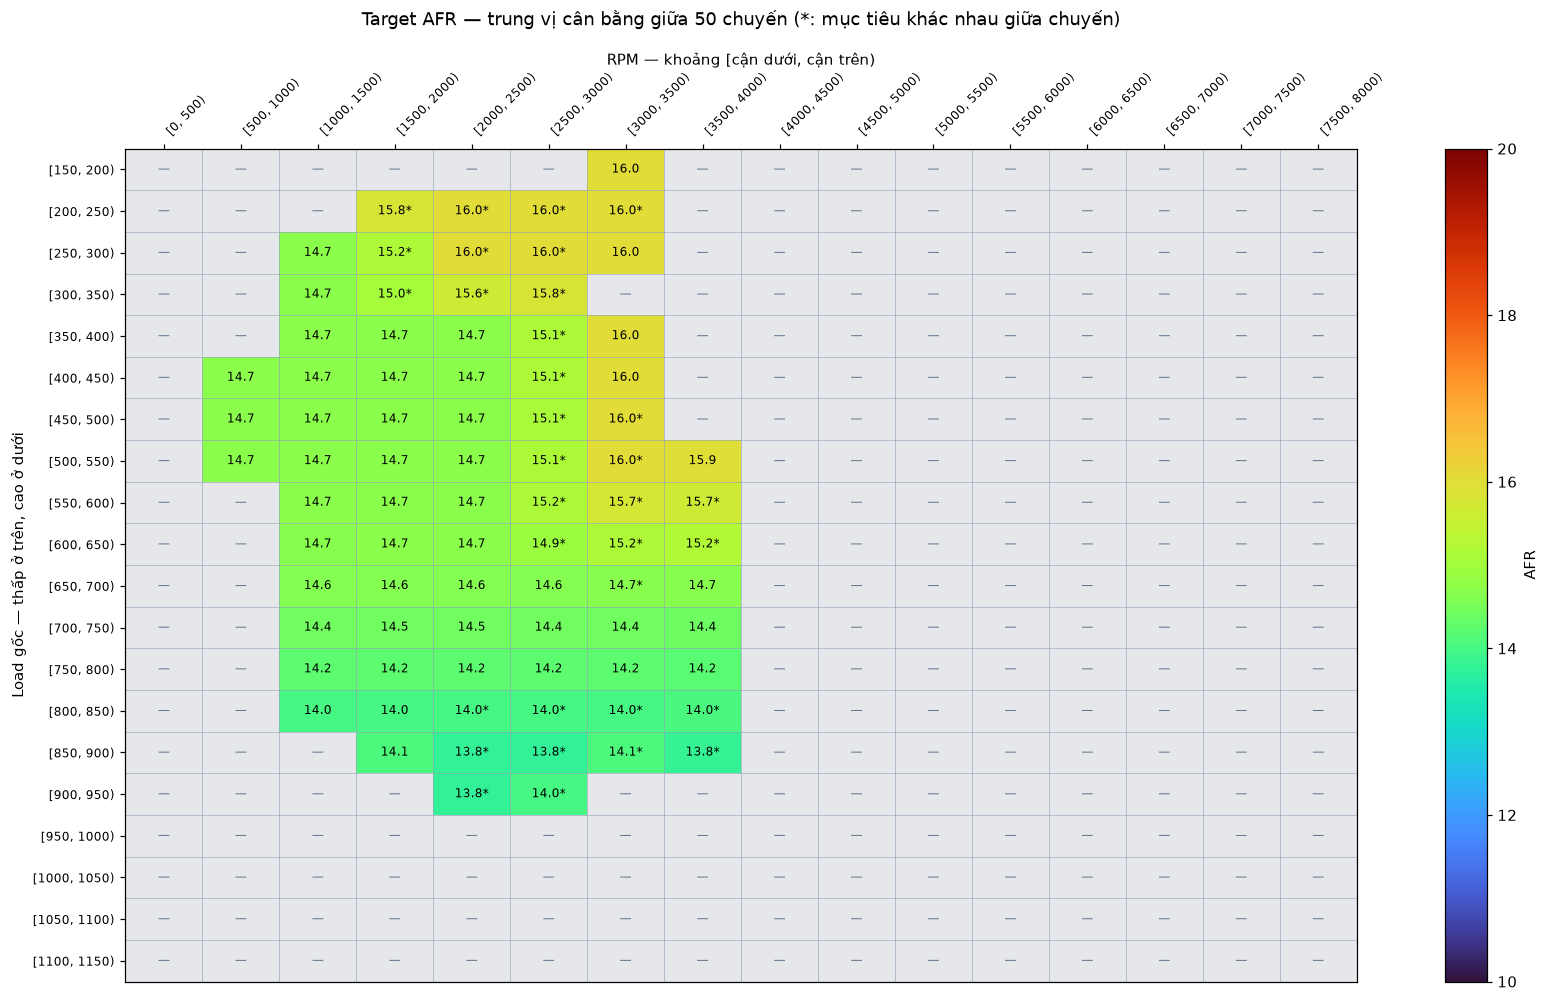

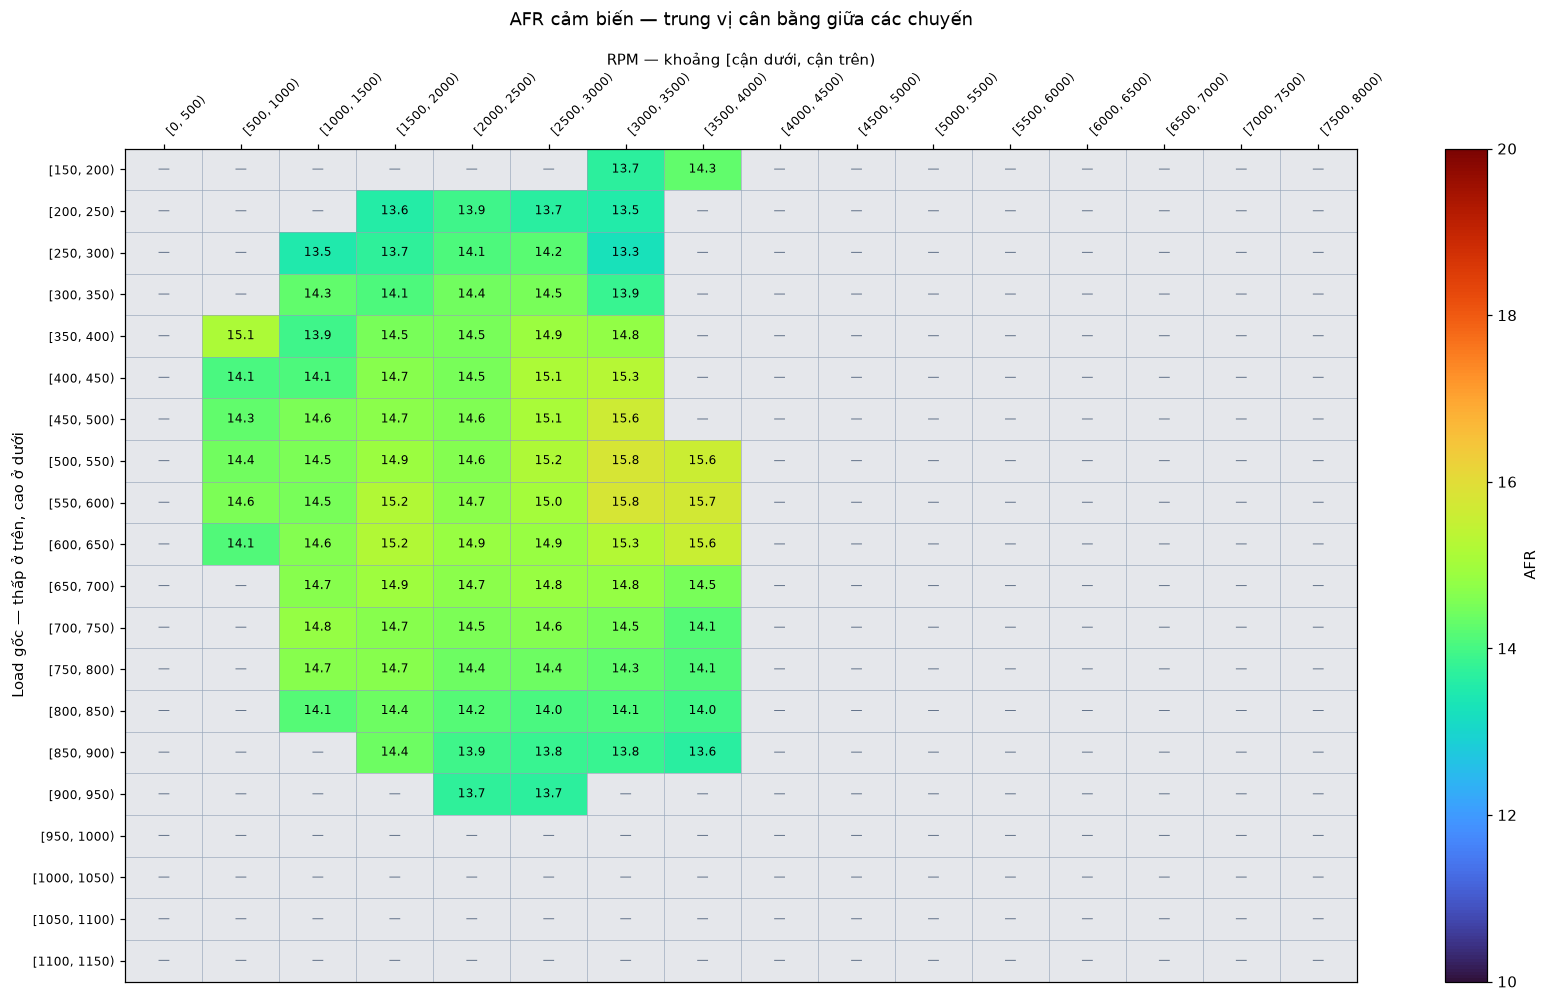

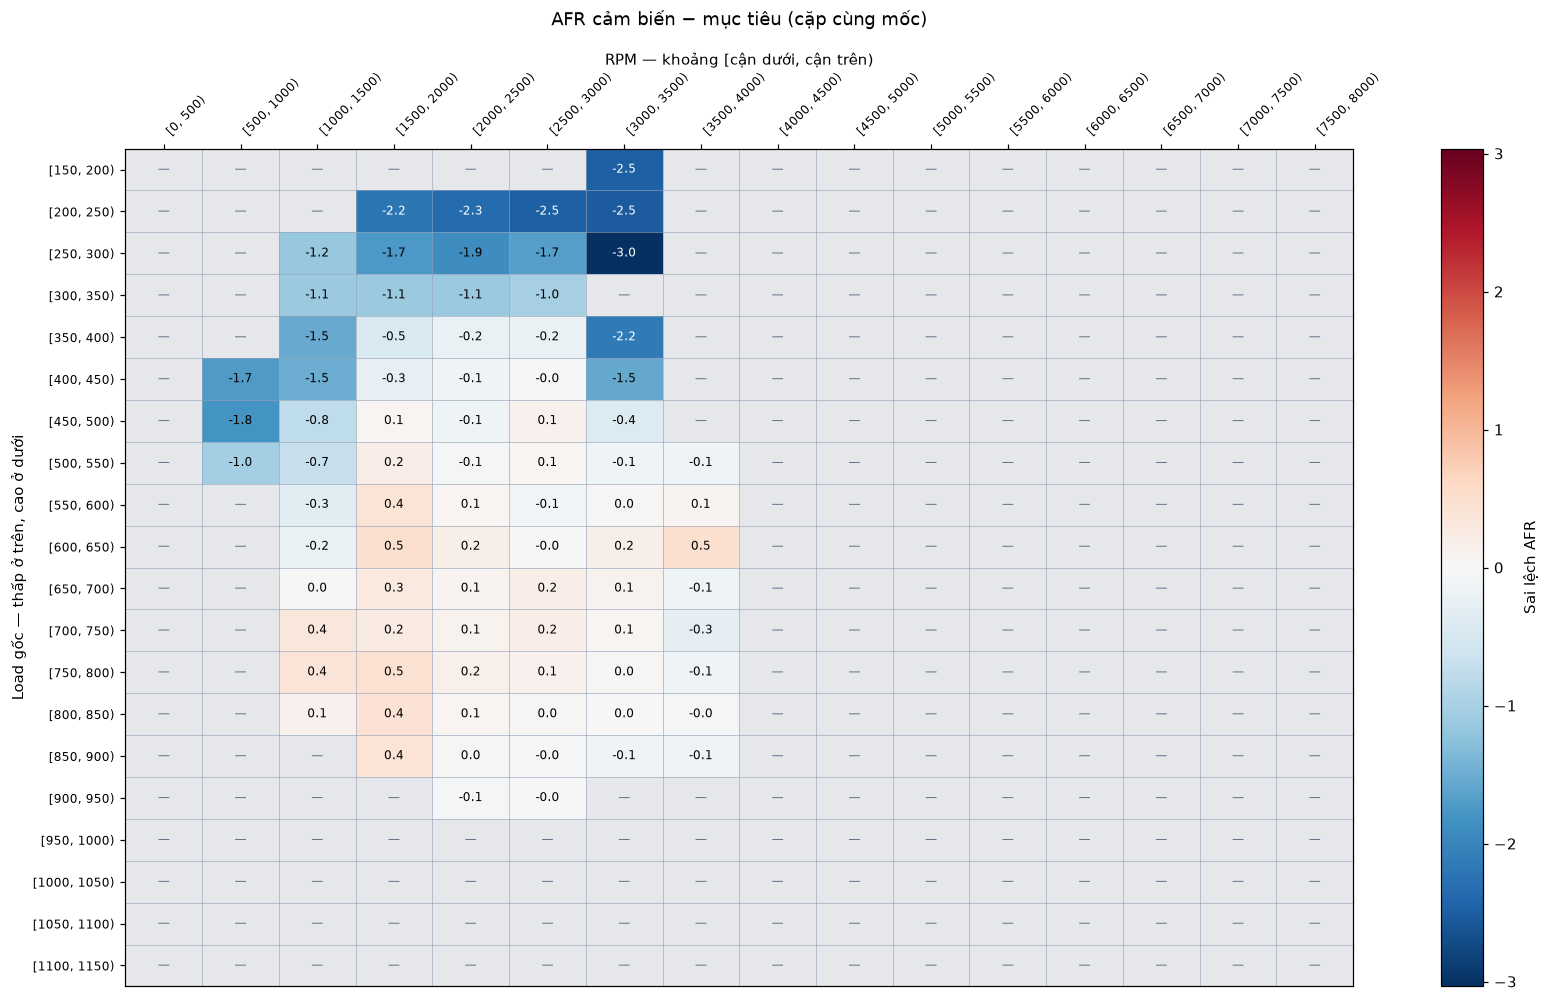

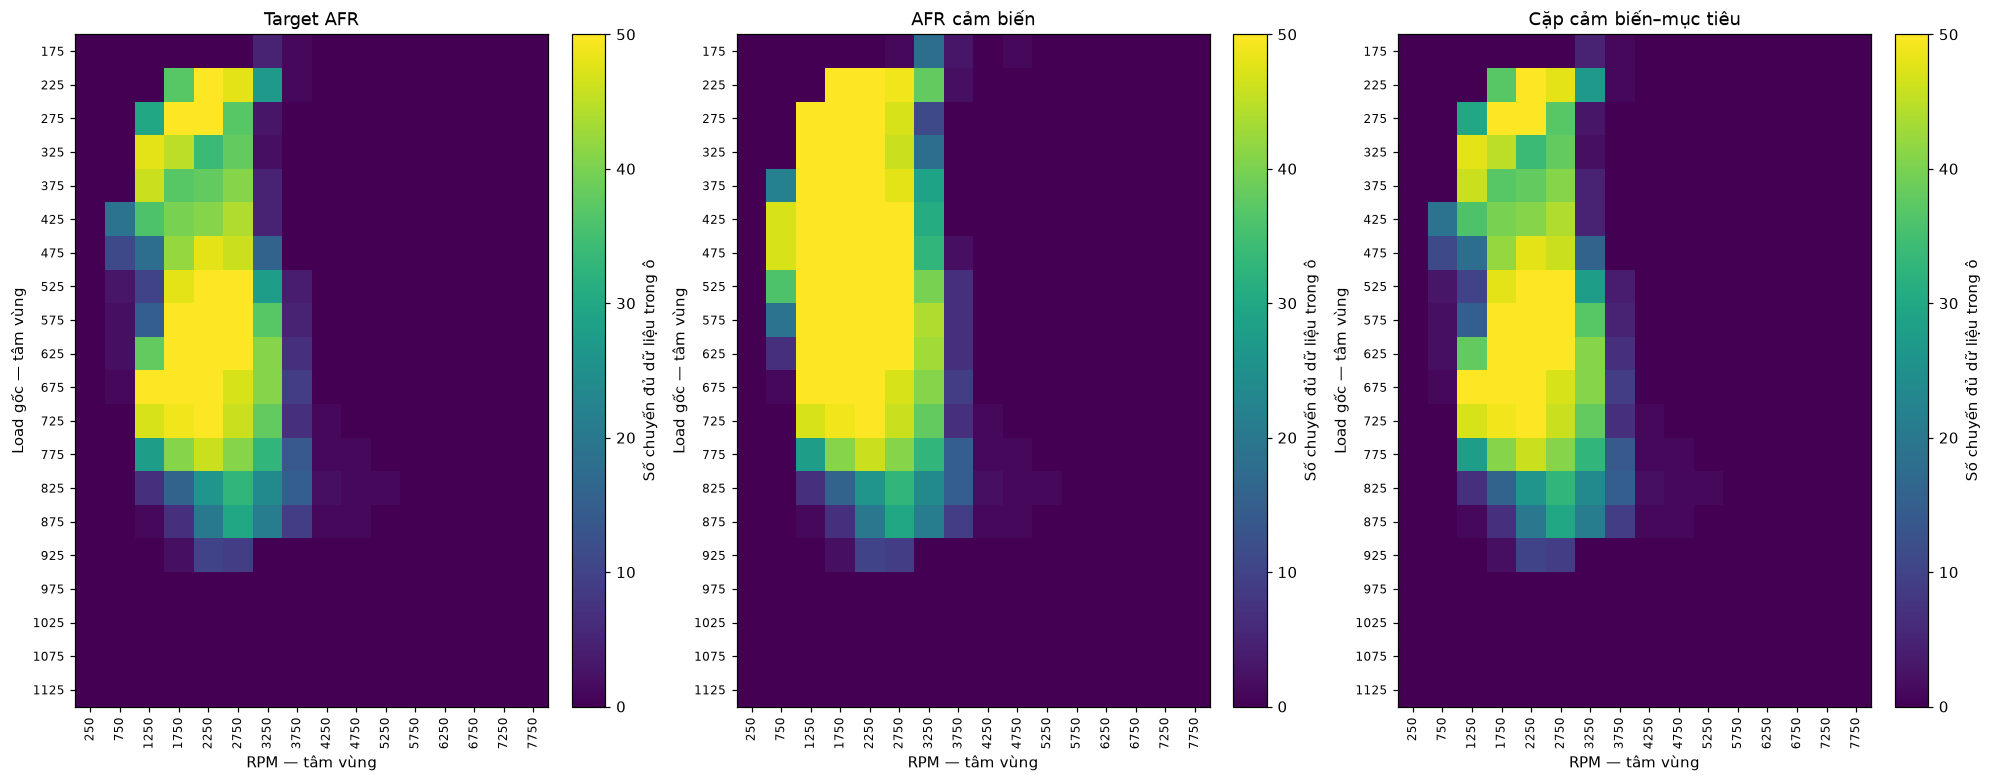

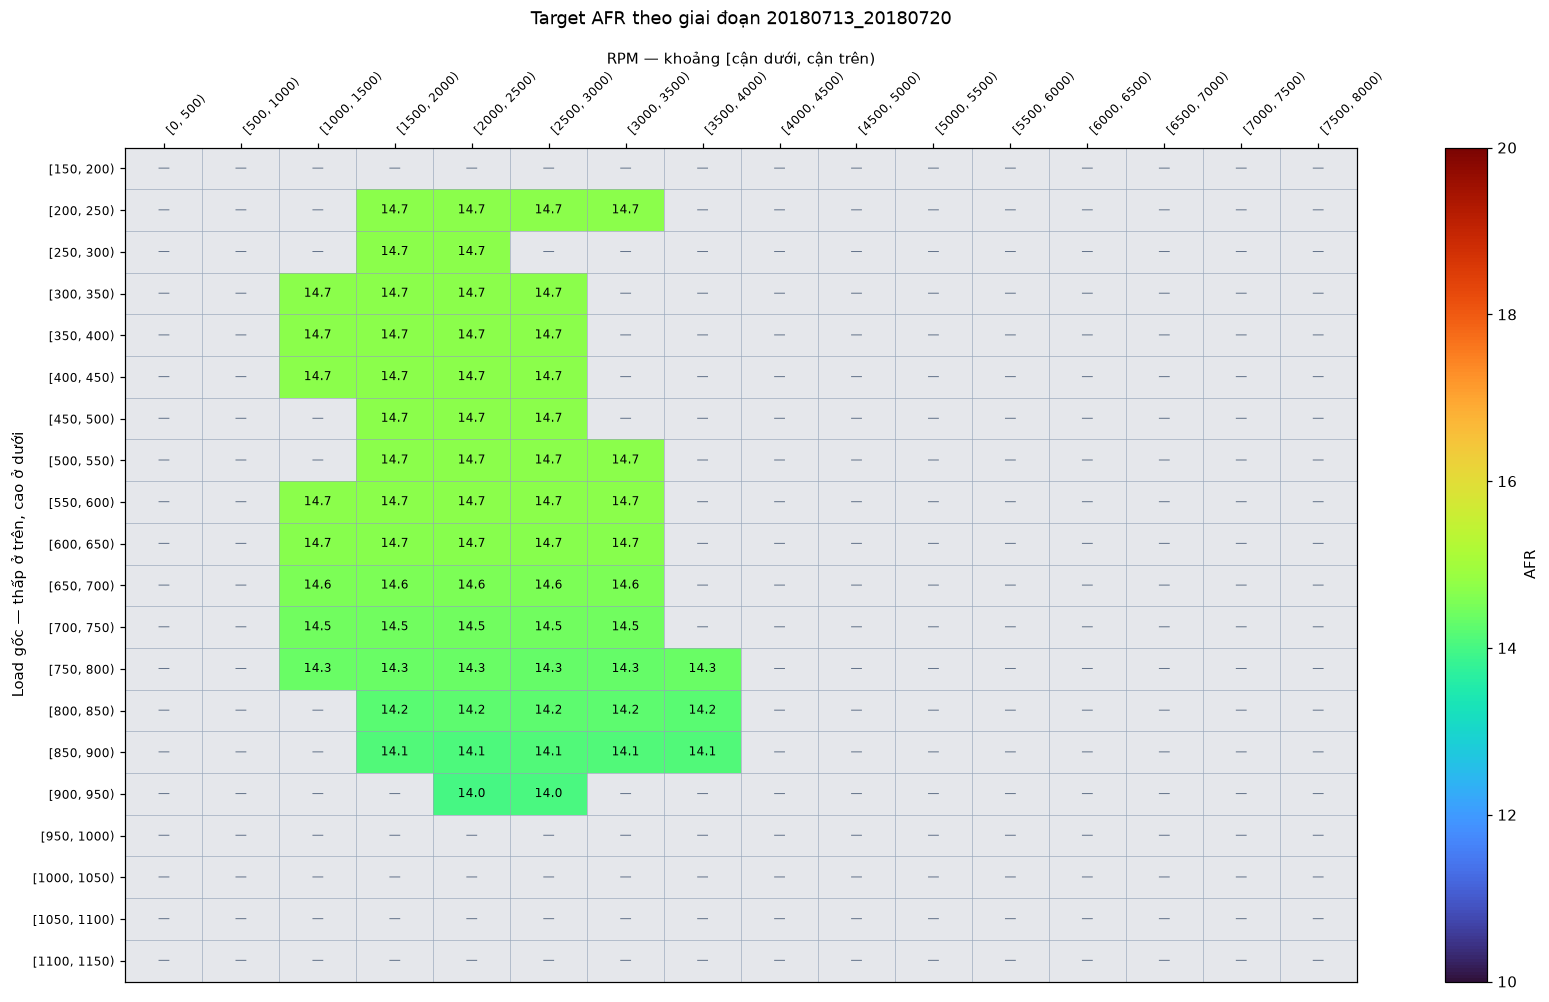

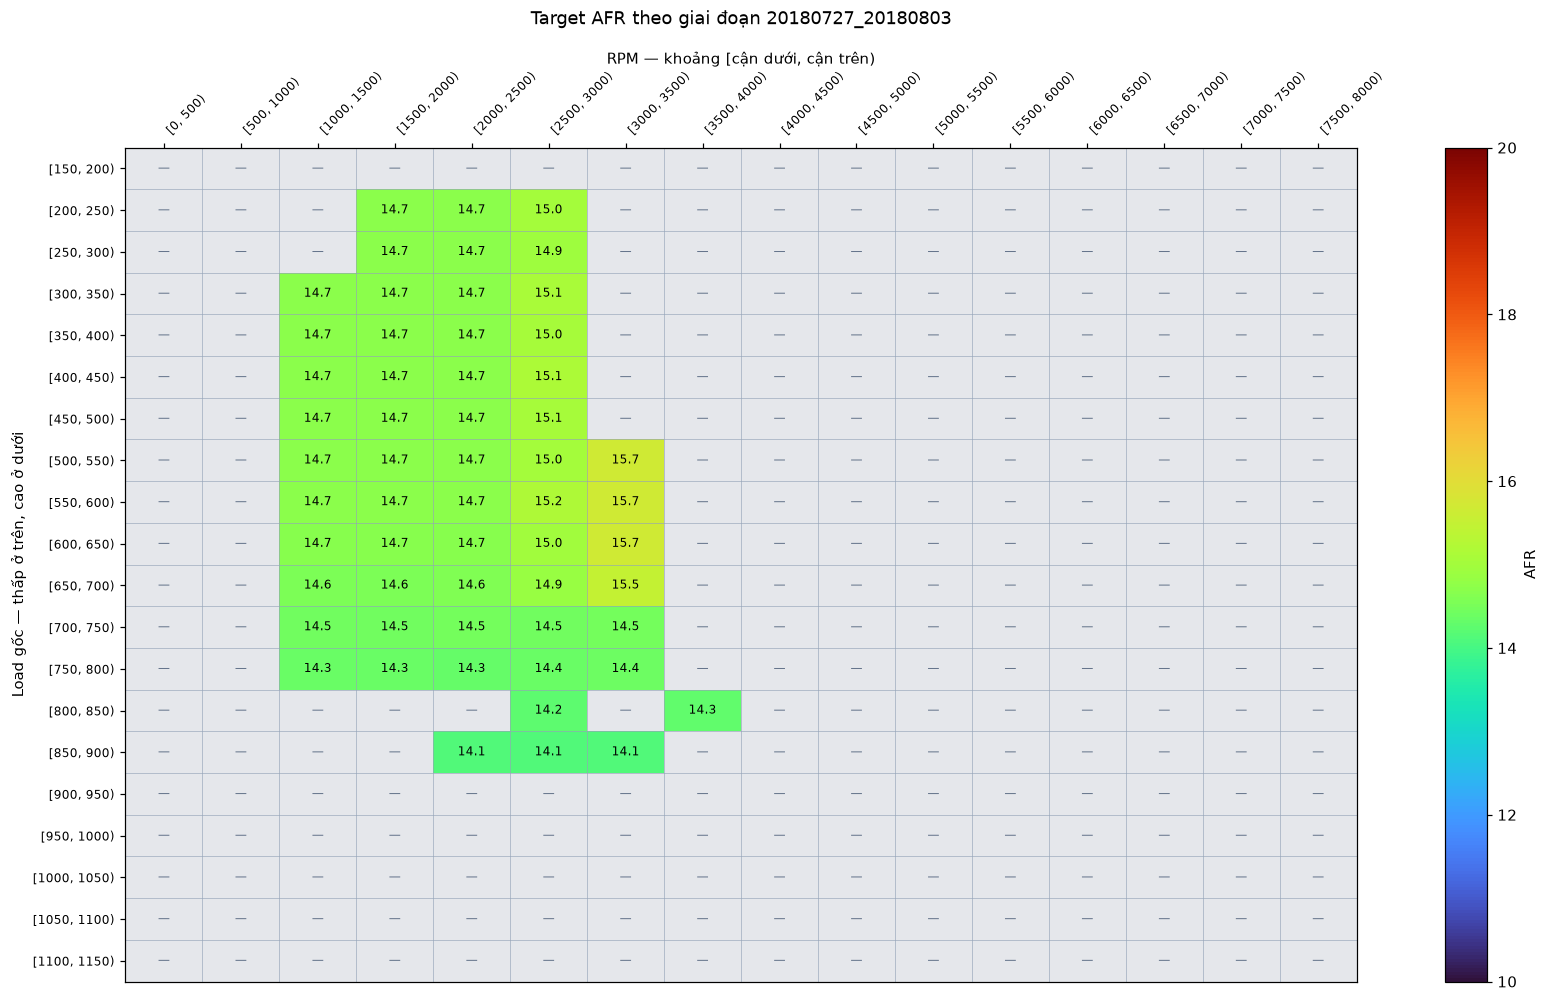

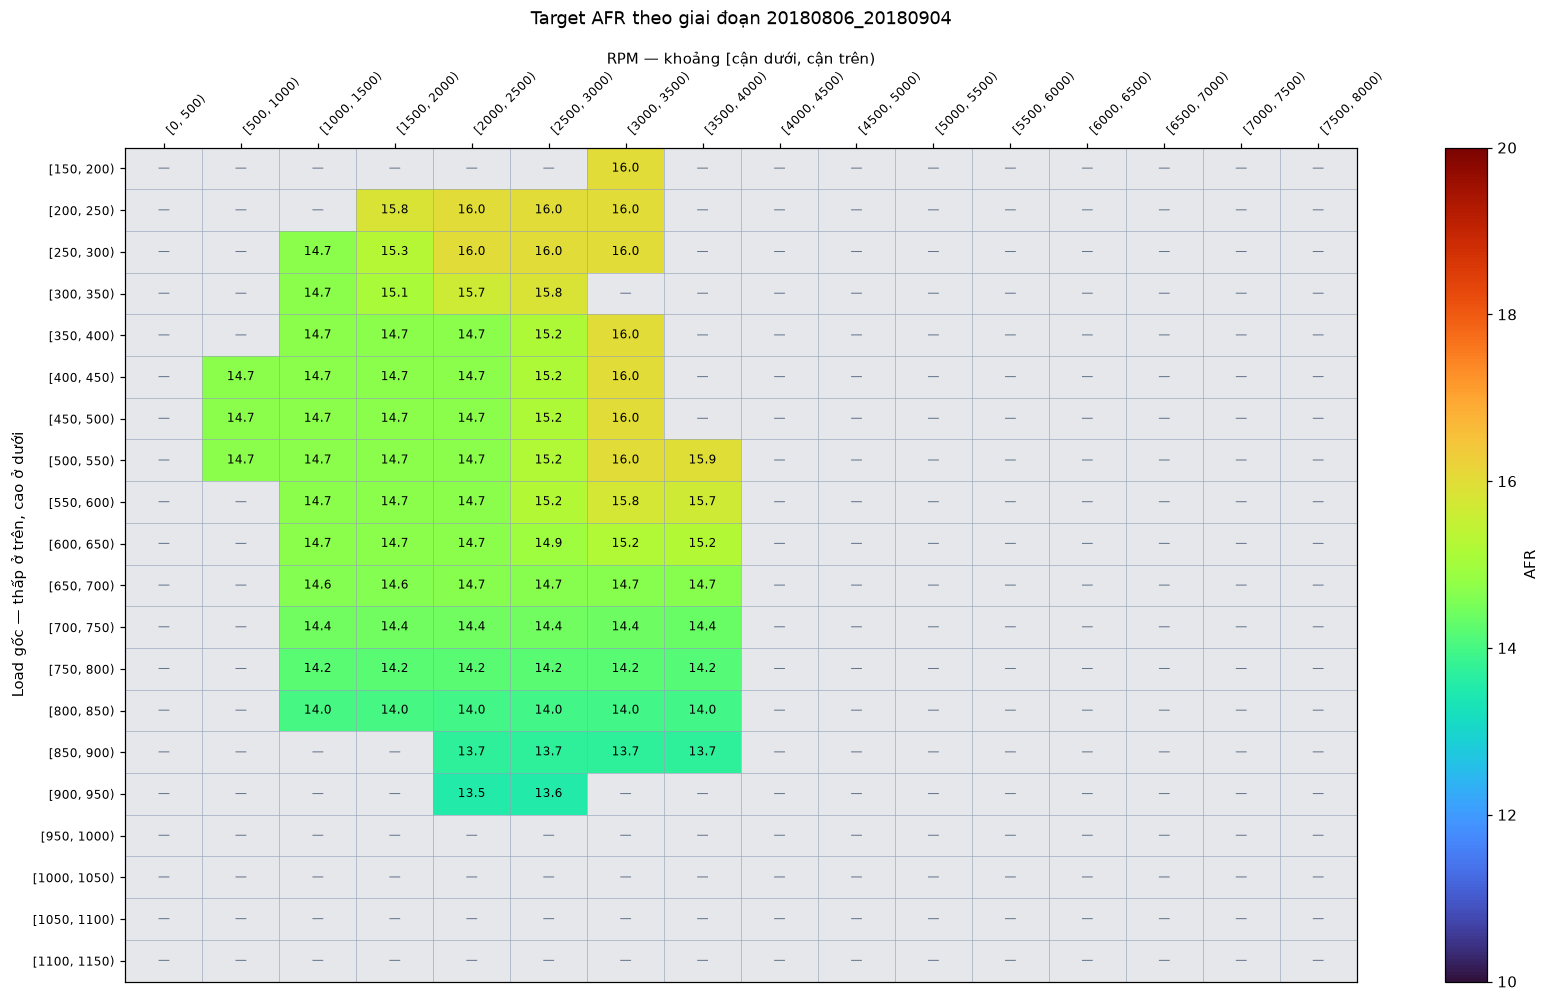

In [22]:
multi_map_overview = multi_summary.groupby("metric").agg(
    cells_observed=("n_trips_observed", "size"),
    cells_supported=("supported", "sum"),
    target_variable_cells=("target_variable", "sum"),
    max_supporting_trips=("n_trips", "max"),
)
multi_map_overview["grid_cells"] = len(multi_result["rpm_bins"]) * len(multi_result["load_bins"])
multi_map_overview["supported_grid_pct"] = (
    multi_map_overview.cells_supported / multi_map_overview.grid_cells * 100
)
display(multi_map_overview.round(2))
display(multi_summary.loc[multi_summary.metric.eq("target") & multi_summary.target_variable,
    ["load_bin", "rpm_bin", "value", "n_trips", "n_dates", "trip_iqr", "trip_p90_p10"]]
    .sort_values("trip_p90_p10", ascending=False).head(12).round(3))
multi_figures = plot_tables(multi_result)
plt.show()

### 10.3. Kiểm tra mục tiêu thay đổi theo thời gian

Các file ghi nhận mức TargetAFR cao nhất lần lượt là 1000, 1068 và 1088 trong
ba giai đoạn. Sau quy đổi, các giá trị đó là 14,7; 15,6996 và 15,9936 AFR.
Đây là các cực đại quan sát, không phải mục tiêu ở mọi ô. So sánh những vùng
được hỗ trợ ở cả ba giai đoạn để giảm việc so sánh các vùng không tương ứng.
Không trộn các giá trị đó thành một bảng được tuyên bố là mục tiêu tốt nhất cho xe.

In [23]:
multi_periods = multi_result["period_comparison"]
multi_period_report = multi_periods.groupby("period").agg(
    observed_cells=("value", "size"), supported_cells=("supported", "sum"),
)
display(multi_period_report)
period_values = multi_periods.loc[multi_periods.supported].pivot(
    index=["load_bin", "rpm_bin"], columns="period", values="value"
)
period_common = period_values.dropna().copy()
period_common["period_max_minus_min_afr"] = period_common.max(axis=1) - period_common.min(axis=1)
period_common.to_csv(multi_output / "common_cells_period_comparison.csv")
display(period_common.sort_values("period_max_minus_min_afr", ascending=False).head(15).round(3))
print("Số vùng được hỗ trợ ở cả ba giai đoạn:", len(period_common))
print("Hình và CSV riêng từng giai đoạn đã được lưu trong", multi_output)

,observed_cells,supported_cells
period,,
20180713_20180720,181,63
20180727_20180803,117,57
20180806_20180904,186,80


period            20180713_20180720  ...  period_max_minus_min_afr
load_bin rpm_bin                     ...                          
4        4                   14.700  ...                     1.294
         5                   14.700  ...                     1.294
5        4                   14.700  ...                     1.294
10       6                   14.700  ...                     1.294
4        3                   14.700  ...                     1.139
6        5                   14.700  ...                     1.132
11       6                   14.700  ...                     1.080
12       6                   14.671  ...                     1.029
6        4                   14.700  ...                     0.963
13       6                   14.568  ...                     0.911
5        3                   14.700  ...                     0.581
11       5                   14.700  ...                     0.544
10       5                   14.700  ...                     0.515
8        5                   14.700  ...                     0.492
9        5                   14.700  ...                     0.485

[15 rows x 4 columns]

Số vùng được hỗ trợ ở cả ba giai đoạn: 54
Hình và CSV riêng từng giai đoạn đã được lưu trong outputs\all_trips_afr


### 10.4. Kiểm chứng bằng các ngày chưa dùng để xây bảng

Giữ riêng khoảng 20% ngày cuối, bảo đảm hai chiều đi cùng ngày không bị chia sang
cả tập xây bảng và kiểm chứng. Chỉ dùng các ngày trước để lập bảng dự đoán.
Đối chiếu với trung vị chuyến×vùng của ngày giữ lại; tính MAE và bias trong từng
chuyến rồi trung bình giữa chuyến. Coverage là tỷ lệ vùng kiểm chứng đủ điều kiện
có giá trị dự đoán từ bảng trước đó. Vùng không dự đoán được vẫn được tính trong
mẫu số coverage, không biến thành sai số bằng 0.

Đây là kiểm chứng khả năng tái hiện số đo lịch sử, không chứng minh hiệu chỉnh
động cơ đúng. Mục tiêu có thể thay đổi theo thời gian. Sau kiểm chứng, bảng cuối
được xây lại từ cả 50 chuyến; thông tin ngày giữ lại vẫn được lưu trong settings.

In [24]:
print("Ngày giữ lại:", ", ".join(multi_result["heldout_dates"]))
display(multi_result["validation"].round(4))
assert multi_result["validation"].coverage_pct.between(0, 100).all()
assert multi_result["validation"].predicted_trip_cells.le(
    multi_result["validation"].eligible_test_trip_cells
).all()

Ngày giữ lại: 2018-08-17, 2018-08-20, 2018-08-21, 2018-08-23, 2018-08-24, 2018-09-04


,metric,train_trips,heldout_trips,heldout_dates,eligible_test_trip_cells,predicted_trip_cells,coverage_pct,equal_trip_mae_afr,equal_trip_bias_afr,test_trips_with_predictions
0,target,39,11,6,675,644,95.4074,0.1656,0.0942,11
1,measured,39,11,6,752,746,99.2021,0.3116,0.0165,11
2,error,39,11,6,675,644,95.4074,0.3011,0.0414,11


### 10.5. Kiểm tra kết quả đã lưu và các bảng cần đọc

Các file chính trong `outputs/all_trips_afr/`:

- `target_afr_map.csv` và `.png`: mục tiêu tổng hợp, cân bằng giữa chuyến.
- `measured_afr_map.csv` và `.png`: AFR cảm biến tổng hợp.
- `error_afr_map.csv`, `afr_error_map.png`: sai lệch theo cặp.
- `trip_coverage.png`, các CSV `n_trips` và `trip_p90_p10`: độ phủ và mức khác biệt.
- Các bảng theo giai đoạn: đối chiếu khi mục tiêu thay đổi theo thời gian.
- `trip_quality.csv`, `channel_quality.csv`, `trip_cell_statistics.csv`,
  `combined_cell_statistics.csv`: truy vết từ bảng tổng hợp về từng chuyến.
- `validation_summary.csv`: kết quả kiểm chứng theo ngày.
- `aligned_trips/*.csv.gz`: 50 bảng đã xử lý riêng, gồm cột gốc, AFR quy đổi,
  thời điểm nguồn, tuổi giá trị và cờ. Đọc bằng `pd.read_csv(path, compression="gzip")`.
- `settings.json`: ngưỡng, công thức, cách gộp, giả thiết và ngày kiểm chứng.

Bảng tổng hợp cho biết những gì dữ liệu hỗ trợ. Vùng thiếu dữ liệu vẫn để trống;
chưa tạo công thức sửa nhiên liệu hoặc đề xuất mục tiêu mới cho xe.

In [25]:
assert len(list((multi_output / "aligned_trips").glob("*.csv.gz"))) == 50
for metric in ["target", "measured", "error"]:
    matrix = multi_result["maps"][metric]
    saved = pd.read_csv(multi_output / f"{metric}_afr_map.csv", index_col=0)
    np.testing.assert_allclose(saved.to_numpy(), matrix.to_numpy(), equal_nan=True)
    supported_cells = multi_summary.loc[multi_summary.metric.eq(metric), "supported"].sum()
    assert matrix.notna().sum().sum() == supported_cells
    assert matrix.notna().any().any(), f"Bảng {metric} chưa có vùng đủ dữ liệu"
print("Đã kiểm tra đủ 50 chuyến, các bảng CSV khớp số liệu và giữ nguyên ô khuyết.")
print("Kết quả cuối:", multi_output.resolve())
display(multi_map_overview.round(2))

Đã kiểm tra đủ 50 chuyến, các bảng CSV khớp số liệu và giữ nguyên ô khuyết.
Kết quả cuối: D:\ECU_data\outputs\all_trips_afr


,cells_observed,cells_supported,target_variable_cells,max_supporting_trips,grid_cells,supported_grid_pct
metric,,,,,,
error,199,81,0,50,320,25.31
measured,201,86,0,50,320,26.88
target,199,81,33,50,320,25.31
